# 환경 설정

## 한글화 코드

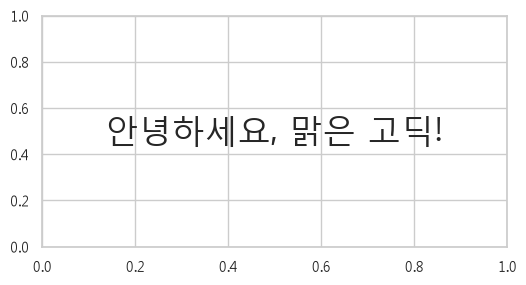

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

# seaborn 스타일을 먼저 적용
sns.set_theme(style="whitegrid")

# Windows 한글 글꼴 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 한글 표시 확인
plt.figure(figsize=(6, 3))
plt.text(
    0.5, 0.5,
    "안녕하세요, 맑은 고딕!",
    ha="center",
    va="center",
    size=24
)
plt.show()

## MySQL 연결

In [2]:
import pandas as pd
from getpass import getpass
from sqlalchemy import create_engine, URL, text

url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("MySQL 비밀번호: "),
    host="localhost",
    port=3306,
    database="final",
    query={"charset": "utf8mb4"},
)

engine = create_engine(url, pool_pre_ping=True)

# 연결 확인
with engine.connect() as conn:
    print(conn.execute(text("SELECT VERSION()")).scalar())

8.0.37


In [3]:
query = "SELECT * FROM accounts_user LIMIT 5"

with engine.connect() as conn:
    df = pd.read_sql_query(text(query), conn)

df.head()

,id,is_superuser,is_staff,gender,point,friend_id_list,is_push_on,created_at,block_user_id_list,hide_user_id_list,ban_status,report_count,alarm_count,pending_chat,pending_votes,group_id
0,831956,1,1,None,600,"[1292473, 913158, 1488461, 1064695, 1043565, 1...",0,2023-03-29 03:44:14.047130,[],[],N,0,0,0,0,NaN
1,831962,0,0,F,2248,"[833025, 832642, 982531, 879496, 838541, 83752...",1,2023-03-29 05:18:56.162368,[],[],N,253,40878,5499,110,12.0
2,832151,0,0,M,1519,"[838785, 982531, 882567, 879496, 838541, 83649...",0,2023-03-29 12:56:34.989468,[],[],N,0,37,0,47,1.0
3,832340,0,0,F,57,"[841345, 982531, 838785, 963714, 882567, 83252...",1,2023-03-29 12:56:35.020790,[],[],N,0,19,0,21,1.0
4,832520,0,0,M,1039,"[874050, 849763, 874212, 844297, 838541, 84004...",0,2023-03-29 12:56:35.049311,[],[],N,0,29,0,15,12.0


## DataFrame에 저장

In [4]:
import pandas as pd
from sqlalchemy import text

params = {
    "start_at": "2023-05-04 00:00:00",
    "end_at": "2024-05-06 00:00:00",
}

queries = {
    "polls_question": """
        SELECT
            id,
            TRIM(question_text) AS question_text,
            created_at
        FROM final.polls_question
    """,

    "polls_questionreport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            question_id,
            user_id
        FROM final.polls_questionreport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_usercandidate": """
        SELECT
            id,
            created_at,
            question_piece_id,
            user_id
        FROM final.polls_usercandidate
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionset": """
        SELECT
            id,
            question_piece_id_list,
            opening_time,
            status,
            user_id
        FROM final.polls_questionset
        WHERE opening_time >= created_at
          AND status = 'F'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionpiece": """
        SELECT
            id,
            is_voted,
            question_id,
            is_skipped
        FROM final.polls_questionpiece
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_userquestionrecord": """
        SELECT
            id,
            status,
            created_at,
            chosen_user_id,
            question_id,
            user_id,
            question_piece_id,
            has_read,
            answer_status,
            answer_updated_at,
            report_count,
            opened_times
        FROM final.accounts_userquestionrecord
        WHERE answer_status <> 'P'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    # 가입일 제한 없이 일반 유저 전체 조회
    "accounts_user": """
        SELECT
            id,
            is_superuser,
            is_staff,
            gender,
            friend_id_list,
            is_push_on,
            created_at,
            block_user_id_list,
            hide_user_id_list,
            ban_status,
            report_count,
            group_id
        FROM final.accounts_user
        WHERE is_superuser = 0
          AND is_staff = 0
    """,

    "accounts_timelinereport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            reported_user_id,
            user_id,
            user_question_record_id
        FROM final.accounts_timelinereport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_school": """
        SELECT
            id,
            student_count,
            school_type
        FROM final.accounts_school
    """,

    "accounts_group": """
        SELECT
            id,
            school_id
        FROM final.accounts_group
    """,

    "accounts_blockrecord": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            block_user_id,
            user_id
        FROM final.accounts_blockrecord
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    # 생성일 컬럼이 없어 전체 조회
    "accounts_attendance": """
        SELECT
            id,
            attendance_date_list,
            user_id
        FROM final.accounts_attendance
    """,
}

dfs = {}

with engine.connect() as conn:
    for table_name, query in queries.items():
        dfs[table_name] = pd.read_sql_query(
            text(query),
            conn,
            params=params,
        )

        df = dfs[table_name]
        print(f"{table_name}: {len(df):,}행 × {len(df.columns)}열")

# 개별 DataFrame 변수
df_question = dfs["polls_question"]
df_questionreport = dfs["polls_questionreport"]
df_usercandidate = dfs["polls_usercandidate"]
df_questionset = dfs["polls_questionset"]
df_questionpiece = dfs["polls_questionpiece"]
df_userquestionrecord = dfs["accounts_userquestionrecord"]
df_user = dfs["accounts_user"]
df_timelinereport = dfs["accounts_timelinereport"]
df_school = dfs["accounts_school"]
df_group = dfs["accounts_group"]
df_blockrecord = dfs["accounts_blockrecord"]
df_attendance = dfs["accounts_attendance"]

polls_question: 5,025행 × 3열
polls_questionreport: 48,928행 × 5열
polls_usercandidate: 4,452,529행 × 4열
polls_questionset: 141,909행 × 5열
polls_questionpiece: 1,177,414행 × 4열
accounts_userquestionrecord: 1,128,249행 × 12열
accounts_user: 677,081행 × 12열
accounts_timelinereport: 208행 × 6열
accounts_school: 5,951행 × 3열
accounts_group: 84,515행 × 2열
accounts_blockrecord: 19,481행 × 5열
accounts_attendance: 349,637행 × 3열


In [5]:
query_attendance = """
SELECT
    id,
    attendance_date_list,
    user_id
FROM final.accounts_attendance
"""

with engine.connect() as conn:
    df_attendance = pd.read_sql_query(text(query_attendance), conn)

dfs["accounts_attendance"] = df_attendance

print(f"accounts_attendance: {len(df_attendance):,}행 × {len(df_attendance.columns)}열")

df_attendance.head()

accounts_attendance: 349,637행 × 3열


,id,attendance_date_list,user_id
0,1,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1446852
1,2,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1359398
2,3,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1501542
3,4,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1507767
4,5,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1287453


# 전처리

## 중복값 확인

In [6]:
duplicate_results = []

for table_name, df in dfs.items():
    duplicate_results.append({
        "테이블": table_name,
        "전체 행 수": len(df),

        # 첫 행을 제외한 추가 중복 행 수
        "전체 컬럼 중복 행 수": int(df.duplicated().sum()),

        # 기본키 중복 및 누락
        "ID 중복 수": (
            int(df["id"].duplicated().sum())
            if "id" in df.columns else pd.NA
        ),
        "ID 결측 수": (
            int(df["id"].isna().sum())
            if "id" in df.columns else pd.NA
        ),
    })

df_duplicate_summary = pd.DataFrame(duplicate_results)

df_duplicate_summary

,테이블,전체 행 수,전체 컬럼 중복 행 수,ID 중복 수,ID 결측 수
0,polls_question,5025,0,0,0
1,polls_questionreport,48928,0,0,0
2,polls_usercandidate,4452529,0,0,0
3,polls_questionset,141909,0,0,0
4,polls_questionpiece,1177414,0,0,0
5,accounts_userquestionrecord,1128249,0,0,0
6,accounts_user,677081,0,0,0
7,accounts_timelinereport,208,0,0,0
8,accounts_school,5951,0,0,0
9,accounts_group,84515,0,0,0


## 질문 합치기 & 불필요한 질문 드랍

In [7]:
import pandas as pd

# 문서에 정리된 중복 질문 묶음 (같은 튜플 = 같은 질문)
DUPLICATE_GROUPS = [
    # 2. 띄어쓰기·문장부호·단순 오타만 다른 묶음
    (779, 3967, 4950), (3297, 4280), (2753, 2754), (1627, 2486), (3330, 4313),
    (2439, 2440), (2399, 2400), (1250, 2338), (1431, 2283), (1407, 2163),
    (1470, 1978), (729, 1966, 3777, 4760), (673, 1883), (3429, 4412), (3987, 4970),

    # 3-1. 어미·조사가 다른 묶음
    (765, 3133), (1042, 2001), (121, 3454, 4437), (741, 1585, 3084, 3085), (891, 3074),
    (1361, 1624), (1085, 3032), (683, 3014), (1031, 3009), (624, 3003),
    (2996, 2997), (982, 2990), (128, 589), (1345, 3256, 4239), (2908, 2909),
    (1529, 2904), (582, 2777), (2691, 3760, 4743), (1336, 2680), (1375, 2668),
    (1284, 2624), (1246, 2615), (1442, 2518, 4039, 5022), (2504, 3632, 4615), (174, 1198),
    (118, 1329), (381, 2404), (1373, 2307), (1509, 2291), (629, 4127, 5110),
    (2237, 2240), (2214, 4133, 5116), (2169, 2170), (611, 2161), (358, 2155),
    (1169, 2081), (2053, 3448, 4431), (502, 3486, 4469), (1001, 1973),
    (1951, 3547, 4530, 3961, 4944), (1948, 1949), (1548, 1946), (1429, 1929, 1930),
    (1900, 1902), (1061, 1894), (1410, 1879), (748, 1848), (613, 1776),
    (896, 1759), (577, 1738), (1456, 1686), (114, 1150), (345, 1165),
    (1301, 3025), (1382, 2317),

    # 3-2. 유의어·어순·어조가 다른 묶음
    (1013, 1221), (298, 1239, 2202, 3979, 4962), (1634, 2099, 3940, 4923), (1630, 1994),
    (246, 3169, 4152), (597, 2540), (119, 2361, 2362), (228, 2327, 3092), (1224, 2125),
    (672, 1808), (1265, 1727, 3375, 4358), (201, 1356), (1347, 3037), (1168, 3283, 4266),
    (322, 2917), (797, 4136, 5119), (1332, 2784), (1207, 2759), (510, 2733, 3134),
    (1552, 2008), (3127, 3209, 4192), (216, 2693), (313, 501), (453, 3123),
    (1148, 2631), (548, 994), (115, 2490), (1220, 2481), (866, 1030),
    (635, 2448), (2441, 3105), (1491, 3100), (2384, 3099), (301, 986),
    (2036, 3228, 4211), (1319, 3533, 4516), (1888, 3176, 4159), (622, 1853),
    (142, 3980, 4963), (492, 2667), (122, 2492), (599, 3741, 4724), (316, 1271),
    (2228, 2229), (180, 1618),

    # 4-3. 일반 구간 내 텍스트 완전 일치
    (782, 3163), (287, 1391, 3160), (1558, 3159), (1632, 3043), (521, 1492),
    (1598, 3103), (1508, 3096), (3084, 3085), (1299, 3073), (197, 763),
    (1309, 3062), (608, 3059), (1029, 3226, 4209), (1359, 3007), (182, 1124),
    (823, 2968), (674, 2967), (1421, 2964), (2958, 2959), (634, 2954),
    (1395, 2948), (831, 2940), (1503, 2924), (1537, 2915), (1599, 2912),
    (1437, 2883), (1641, 2879), (2868, 2869), (1581, 2847), (1628, 2835),
    (1469, 2812), (856, 2809), (2801, 2802), (1533, 2800), (2775, 2776),
    (708, 2761), (838, 1397, 2750), (2720, 2721), (1565, 2702), (553, 1489),
    (746, 2688), (1571, 2634), (1596, 2599), (1244, 2595), (1617, 2590),
    (1383, 2537), (1639, 2530), (1442, 2518), (870, 2503), (2449, 2450),
    (2445, 2446), (2428, 2429), (1273, 2427), (1341, 2396), (1638, 2373),
    (1637, 2314), (1331, 2309), (868, 2259), (684, 2226), (2220, 2221),
    (1453, 2203), (1342, 2188), (1616, 2181), (1337, 2175), (1549, 2173),
    (1190, 2157), (2127, 2128), (1028, 2112), (2098, 3511, 4494), (1403, 2096),
    (2090, 2091), (730, 2087), (1411, 2083), (1499, 2062), (2051, 2052),
    (1440, 2044), (1623, 2032), (2006, 2007), (1436, 1971), (729, 1966),
    (1951, 3547, 4530), (1315, 1933), (1929, 1930), (1640, 1855), (836, 1839),
    (1279, 1830), (790, 1821), (1772, 1773), (1614, 1769), (1398, 1750),
    (1416, 1742), (1446, 1740), (750, 1728), (1349, 1717), (835, 1687),
    (1237, 1629), (1669, 1670), (620, 1664),
]

# 4-2. 분석에서 제거할 ID ("vote", "포인트")
REMOVE_IDS = {
    186, 483, 639, 696, 712, 725, 736, 807, 881, 940, 946, 1139, 1219, 1232, 1320,
    1507, 1591, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1747, 1749, 2129,
    2246, 2565, 2843, 2916, 3200, 3216, 3314, 3353, 3367, 3447, 3564, 3566, 3695,
    3913, 3915, 4033, 4183, 4199, 4297, 4336, 4350, 4430, 4547, 4549, 4678, 4896,
    4898, 5016,
    3956, 4939,
}

# 4-1. 블록 복제 구간: ID 4151~5133 = ID 3168~4150 (+983)
BLOCK_START, BLOCK_END, BLOCK_OFFSET = 3168, 4150, 983


class QuestionIdMapper:
    """중복 질문 ID를 묶음 내 가장 작은 ID로 치환한다.

    - 블록 복제 구간(4151~5133)은 원본 ID(-983)와 같은 묶음으로 본다.
    - 묶음이 서로 이어지면(예: 4950 → 3967 → 779) 하나로 합쳐 가장 작은 ID로 보낸다.
    - "vote", "포인트" ID는 NA로 바꾼다.
    """

    def __init__(self):
        parent = {}

        def find(x):
            parent.setdefault(x, x)
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x

        def union(a, b):
            ra, rb = find(a), find(b)
            if ra != rb:
                # 루트를 항상 작은 ID로 유지 → 루트가 곧 대표 ID
                parent[max(ra, rb)] = min(ra, rb)

        for group in DUPLICATE_GROUPS:
            for qid in group[1:]:
                union(group[0], qid)
        for qid in range(BLOCK_START, BLOCK_END + 1):
            union(qid, qid + BLOCK_OFFSET)

        self.mapping = {qid: find(qid) for qid in parent if find(qid) != qid}
        self.remove_ids = set(REMOVE_IDS)

    def map_id(self, qid):
        """ID 하나를 대표 ID로 바꾼다. 제거 대상이면 None."""
        if qid in self.remove_ids:
            return None
        return self.mapping.get(qid, qid)

    def transform(self, ids):
        """ID 리스트/Series를 대표 ID Series(Int64)로 바꾼다. 제거 대상은 NA."""
        s = ids if isinstance(ids, pd.Series) else pd.Series(ids)
        return s.map(self.map_id).astype("Int64")


In [8]:
mapper = QuestionIdMapper()

# 원본 question_id는 유지
df_questionreport_clean = df_questionreport.copy()

df_questionreport_clean["대표 질문 ID"] = mapper.transform(
    df_questionreport_clean["question_id"]
)

# REMOVE_IDS에 해당하는 행 제외
df_questionreport_clean = df_questionreport_clean.dropna(
    subset=["대표 질문 ID"]
)

In [9]:
# clean 신고 데이터에 포함된 고유 대표 질문 수
print(
    "총 질문 수:",
    f"{df_questionreport_clean['대표 질문 ID'].nunique():,}개",
)

총 질문 수: 2,902개


In [10]:
print(
    "총 질문 수:",
    f"{df_questionreport['question_id'].nunique():,}개",
)

총 질문 수: 3,135개


# EDA

## 전체 질문 신고 순위 확인

### 질문 신고 순위

In [11]:
# 긍정적 사유 제외
positive_mask = (
    df_questionreport["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

df_question_report_top10 = (
    df_questionreport.loc[~positive_mask]
    .groupby("question_id")
    .agg(
        신고_수=("id", "size"),
        고유_신고자_수=("user_id", "nunique"),
    )
    .reset_index()
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "question_id",
            "question_text": "질문명",
        }),
        on="question_id",
        how="left",
        validate="one_to_one",
    )
    .rename(columns={
        "question_id": "질문 ID",
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
    })
    [["질문 ID", "질문명", "신고 수", "고유 신고자 수"]]
    .sort_values(
        ["신고 수", "고유 신고자 수", "질문 ID"],
        ascending=[False, False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

df_question_report_top10

,질문 ID,질문명,신고 수,고유 신고자 수
0,111,마스크가 잘 어울리는 사람은?,891,693
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,791,678
2,398,등빨이 가장 좋은 사람은?,657,554
3,424,어깨가 가장 넓은 사람은?,531,458
4,305,먹방을 가장 잘할 것 같은 사람은?,475,392
5,564,설레면 콧구멍이 커지는 친구는?,338,309
6,144,발냄새가 가장 향긋할 것 같은 사람은?,284,246
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,281,243
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,256,209
9,479,치킨 중독인 것 같은 사람은?,235,196


In [12]:
mapper = QuestionIdMapper()

# 원본은 유지하고 분석용 복사본 생성
df_reports_mapped = df_questionreport_clean.copy()

df_reports_mapped["대표 질문 ID"] = mapper.transform(
    df_reports_mapped["question_id"]
)

# 긍정적 사유 제외
positive_mask = (
    df_reports_mapped["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

# REMOVE_IDS 제외 + 긍정적 사유 제외
df_reports_mapped = df_reports_mapped.loc[
    df_reports_mapped["대표 질문 ID"].notna()
    & ~positive_mask
].copy()

# 대표 질문 ID별 신고 집계
df_question_report_top10 = (
    df_reports_mapped
    .groupby("대표 질문 ID")
    .agg(
        신고_수=("id", "size"),
        고유_신고자_수=("user_id", "nunique"),
    )
    .reset_index()
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
    .rename(columns={
        "대표 질문 ID": "질문 ID",
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
    })
    [["질문 ID", "질문명", "신고 수", "고유 신고자 수"]]
    .sort_values(
        ["신고 수", "고유 신고자 수", "질문 ID"],
        ascending=[False, False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

df_question_report_top10

,질문 ID,질문명,신고 수,고유 신고자 수
0,111,마스크가 잘 어울리는 사람은?,891,693
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,791,678
2,398,등빨이 가장 좋은 사람은?,657,554
3,424,어깨가 가장 넓은 사람은?,531,458
4,305,먹방을 가장 잘할 것 같은 사람은?,475,392
5,564,설레면 콧구멍이 커지는 친구는?,338,309
6,144,발냄새가 가장 향긋할 것 같은 사람은?,284,246
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,281,243
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,256,209
9,479,치킨 중독인 것 같은 사람은?,235,196


### 질문 신고 사유 순위

In [13]:
# 긍정적 사유를 제외한 질문 신고 사유 순위
reasons = (
    df_questionreport["reason"]
    .astype("string")
    .str.strip()
    .fillna("사유 미기재")
    .replace("", "사유 미기재")
)

df_question_report_reason_ranking = (
    reasons.loc[
        reasons.ne("어떻게 이런 생각을? 이 질문 최고!")
    ]
    .value_counts()
    .rename_axis("신고 사유")
    .reset_index(name="신고 수")
)

total_reports = df_question_report_reason_ranking["신고 수"].sum()

df_question_report_reason_ranking["비율(%)"] = (
    df_question_report_reason_ranking["신고 수"]
    / total_reports * 100
    if total_reports else float("nan")
)

df_question_report_reason_ranking.round(2)

,신고 사유,신고 수,비율(%)
0,그냥 싫어,28446,58.6
1,나랑 맞지 않는 질문인 것 같음,9541,19.65
2,불쾌한 질문 내용,5386,11.09
3,자꾸 같은 내용의 질문 반복,3202,6.6
4,한 친구가 질문을 반복적으로 보냄,1701,3.5
5,이 질문은 재미없어요,92,0.19
6,기타,85,0.18
7,불쾌한 내용이 포함되어 있음,72,0.15
8,오타가 있음,11,0.02
9,선정적이거나 자극적인 질문,9,0.02


## 학생들의 신고·차단 행동 패턴

### 성별에 따른 질문 신고 Top10

In [62]:
# 질문 신고에 신고자 성별·질문명 연결
df_gender_reports = (
    df_questionreport.loc[
        df_questionreport["reason"]
        .astype("string")
        .str.strip()
        .eq("불쾌한 질문 내용")
        .fillna(False)
    ]
    .merge(
        df_user[["id", "gender"]].rename(columns={"id": "user_id"}),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "question_id",
            "question_text": "질문명",
        }),
        on="question_id",
        how="left",
        validate="many_to_one",
    )
)

def get_gender_top10(gender, label):
    return (
        df_gender_reports.loc[
            df_gender_reports["gender"].eq(gender)
        ]
        .groupby(["question_id", "질문명"], dropna=False)
        .size()
        .reset_index(name=f"{label} 신고 수")
        .sort_values(
            [f"{label} 신고 수", "question_id"],
            ascending=[False, True],
        )
        .head(10)
        .rename(columns={
            "question_id": f"{label} 질문 ID",
            "질문명": f"{label} 질문명",
        })
        .reset_index(drop=True)
    )

df_gender_question_top10 = pd.concat(
    [
        get_gender_top10("F", "여학생"),
        get_gender_top10("M", "남학생"),
    ],
    axis=1,
)

print(
    "성별 확인 불가 신고:",
    f"{df_gender_reports['gender'].isna().sum():,}건",
)

df_gender_question_top10

성별 확인 불가 신고: 0건


,여학생 질문 ID,여학생 질문명,여학생 신고 수,남학생 질문 ID,남학생 질문명,남학생 신고 수
0,398,등빨이 가장 좋은 사람은?,198,410,발냄새가 호두과자 냄새일 것 같은 사람은?,108
1,111,마스크가 잘 어울리는 사람은?,190,111,마스크가 잘 어울리는 사람은?,37
2,410,발냄새가 호두과자 냄새일 것 같은 사람은?,176,477,항상 냄새를 맡으려고 하는 친구는?,29
3,424,어깨가 가장 넓은 사람은?,141,564,설레면 콧구멍이 커지는 친구는?,28
4,305,먹방을 가장 잘할 것 같은 사람은?,100,138,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,25
5,564,설레면 콧구멍이 커지는 친구는?,75,108,가장 매력적인 사람은?,24
6,538,이모티콘만 보고 알아서 상상해서 골라봐,69,144,발냄새가 가장 향긋할 것 같은 사람은?,24
7,362,땀냄새가 가장 좋을 것 같은 사람은?,51,305,먹방을 가장 잘할 것 같은 사람은?,23
8,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,51,109,와플을 좋아하는 친구는?,22
9,138,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,46,416,발가락에서 페브리즈향이 날 것 같은 사람은?,22


#### 새로운 기준의 성별 질문 신고 Top10

In [64]:
# 포함할 신고 사유
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 대표 질문 ID가 적용된 clean 데이터 사용
df_gender_reports = (
    df_questionreport_clean.loc[
        df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .dropna(subset=["대표 질문 ID"])
    .merge(
        df_user[["id", "gender"]].rename(columns={"id": "user_id"}),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
    )
)


def get_gender_top10(gender, label):
    return (
        df_gender_reports.loc[
            df_gender_reports["gender"].eq(gender)
        ]
        .groupby(["대표 질문 ID", "질문명"], dropna=False)
        .size()
        .reset_index(name=f"{label} 신고 수")
        .sort_values(
            [f"{label} 신고 수", "대표 질문 ID"],
            ascending=[False, True],
        )
        .head(10)
        .rename(columns={
            "대표 질문 ID": f"{label} 대표 질문 ID",
            "질문명": f"{label} 질문명",
        })
        .reset_index(drop=True)
    )


df_gender_question_top10 = pd.concat(
    [
        get_gender_top10("F", "여학생"),
        get_gender_top10("M", "남학생"),
    ],
    axis=1,
)

print(
    "성별 확인 불가 신고:",
    f"{df_gender_reports['gender'].isna().sum():,}건",
)

df_gender_question_top10

성별 확인 불가 신고: 0건


,여학생 대표 질문 ID,여학생 질문명,여학생 신고 수,남학생 대표 질문 ID,남학생 질문명,남학생 신고 수
0,111,마스크가 잘 어울리는 사람은?,639,410,발냄새가 호두과자 냄새일 것 같은 사람은?,290
1,398,등빨이 가장 좋은 사람은?,611,111,마스크가 잘 어울리는 사람은?,206
2,424,어깨가 가장 넓은 사람은?,477,564,설레면 콧구멍이 커지는 친구는?,89
3,410,발냄새가 호두과자 냄새일 것 같은 사람은?,468,144,발냄새가 가장 향긋할 것 같은 사람은?,85
4,305,먹방을 가장 잘할 것 같은 사람은?,369,465,어부가 될 가능성이 가장 높은 사람은?,81
5,564,설레면 콧구멍이 커지는 친구는?,238,460,농부가 될 가능성이 가장 높은 사람은?,80
6,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,203,305,먹방을 가장 잘할 것 같은 사람은?,76
7,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,188,516,매일 공유킥보드 타고 다니는 친구는?,74
8,144,발냄새가 가장 향긋할 것 같은 사람은?,182,476,거의 움직이지 않는 친구는?,73
9,479,치킨 중독인 것 같은 사람은?,182,477,항상 냄새를 맡으려고 하는 친구는?,68


### 학급에 따른 질문 신고 Top10

In [15]:
df_school_reports_check = (
    df_questionreport.loc[
        df_questionreport["reason"]
        .astype("string")
        .str.strip()
        .eq("불쾌한 질문 내용")
        .fillna(False)
    ]
    .merge(
        df_user[["id", "gender", "group_id"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(
            columns={"id": "question_id"}
        ),
        on="question_id",
        how="left",
        validate="many_to_one",
    )
    .dropna(subset=["school_type", "gender"])
)

top10_m = (
    df_school_reports_check.loc[
        df_school_reports_check["school_type"].eq("M"),
        "question_text",
    ]
    .value_counts()
    .head(10)
    .reset_index()
)
top10_m.columns = ["중학교 질문명", "중학교 신고 수"]

top10_h = (
    df_school_reports_check.loc[
        df_school_reports_check["school_type"].eq("H"),
        "question_text",
    ]
    .value_counts()
    .head(10)
    .reset_index()
)
top10_h.columns = ["고등학교 질문명", "고등학교 신고 수"]

df_school_question_top10 = pd.concat(
    [top10_m, top10_h],
    axis=1,
)

df_school_question_top10

,중학교 질문명,중학교 신고 수,고등학교 질문명,고등학교 신고 수
0,발냄새가 호두과자 냄새일 것 같은 사람은?,166,발냄새가 호두과자 냄새일 것 같은 사람은?,118
1,마스크가 잘 어울리는 사람은?,122,마스크가 잘 어울리는 사람은?,105
2,등빨이 가장 좋은 사람은?,103,등빨이 가장 좋은 사람은?,96
3,어깨가 가장 넓은 사람은?,80,어깨가 가장 넓은 사람은?,65
4,먹방을 가장 잘할 것 같은 사람은?,76,먹방을 가장 잘할 것 같은 사람은?,47
5,설레면 콧구멍이 커지는 친구는?,60,설레면 콧구멍이 커지는 친구는?,43
6,이모티콘만 보고 알아서 상상해서 골라봐,54,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,38
7,발가락에서 페브리즈향이 날 것 같은 사람은?,47,발냄새가 가장 향긋할 것 같은 사람은?,36
8,콧수염을 기르면 잘 어울릴 것 같은 사람은?,41,이모티콘만 보고 알아서 상상해서 골라봐,36
9,땀냄새가 가장 좋을 것 같은 사람은?,38,땀냄새가 가장 좋을 것 같은 사람은?,30


#### 새로운 기준의 학급 질문 신고 Top10

In [65]:
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

df_school_reports_check = (
    df_questionreport_clean.loc[
        df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .dropna(subset=["대표 질문 ID"])
    .merge(
        df_user[["id", "gender", "group_id"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
    )
    .dropna(subset=["school_type", "gender"])
)


def get_school_top10(school_type, label):
    return (
        df_school_reports_check.loc[
            df_school_reports_check["school_type"].eq(school_type)
        ]
        .groupby(["대표 질문 ID", "질문명"], dropna=False)
        .size()
        .reset_index(name=f"{label} 신고 수")
        .sort_values(
            [f"{label} 신고 수", "대표 질문 ID"],
            ascending=[False, True],
        )
        .head(10)
        .rename(columns={
            "대표 질문 ID": f"{label} 대표 질문 ID",
            "질문명": f"{label} 질문명",
        })
        .reset_index(drop=True)
    )


df_school_question_top10 = pd.concat(
    [
        get_school_top10("M", "중학교"),
        get_school_top10("H", "고등학교"),
    ],
    axis=1,
)

df_school_question_top10

,중학교 대표 질문 ID,중학교 질문명,중학교 신고 수,고등학교 대표 질문 ID,고등학교 질문명,고등학교 신고 수
0,410,발냄새가 호두과자 냄새일 것 같은 사람은?,407,111,마스크가 잘 어울리는 사람은?,448
1,111,마스크가 잘 어울리는 사람은?,397,410,발냄새가 호두과자 냄새일 것 같은 사람은?,351
2,398,등빨이 가장 좋은 사람은?,319,398,등빨이 가장 좋은 사람은?,313
3,424,어깨가 가장 넓은 사람은?,265,424,어깨가 가장 넓은 사람은?,244
4,305,먹방을 가장 잘할 것 같은 사람은?,248,305,먹방을 가장 잘할 것 같은 사람은?,197
5,564,설레면 콧구멍이 커지는 친구는?,180,564,설레면 콧구멍이 커지는 친구는?,147
6,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,150,144,발냄새가 가장 향긋할 것 같은 사람은?,131
7,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,138,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,119
8,144,발냄새가 가장 향긋할 것 같은 사람은?,136,138,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,110
9,479,치킨 중독인 것 같은 사람은?,132,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,104


### 질문 신고가 유저 신고, 차단, 숨김에 영향이 있는지?

In [17]:
import json
import pandas as pd

user_base = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0)
].copy()

if user_base["id"].isna().any() or user_base["id"].duplicated().any():
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hidden_users(value):
    if isinstance(value, str):
        value = json.loads(value)
    elif isinstance(value, list):
        pass
    elif pd.isna(value):
        return pd.NA
    else:
        raise ValueError("숨김 목록 형식을 확인해 주세요.")

    if value is None:
        return pd.NA

    if not isinstance(value, list):
        raise ValueError("숨김 목록이 리스트 형식이 아닙니다.")

    return len(value) > 0


# 차단한 사람: 차단 기록의 user_id
blocker_ids = set(df_blockrecord["user_id"].dropna())

df_user_action_flags = user_base[["id"]].copy()

df_user_action_flags["차단 실행"] = (
    df_user_action_flags["id"].isin(blocker_ids)
)

# 숨김한 사람: 본인의 숨김 목록에 대상이 한 명 이상 있음
df_user_action_flags["숨김 실행"] = (
    user_base["hide_user_id_list"]
    .apply(has_hidden_users)
    .astype("boolean")
)

total_users = len(df_user_action_flags)

df_user_action_ratio = pd.DataFrame([
    {
        "구분": label,
        "고유 유저 수": int(
            df_user_action_flags[column].fillna(False).sum()
        ),
        "전체 일반 유저 수": total_users,
        "전체 대비 비율(%)": (
            df_user_action_flags[column].fillna(False).sum()
            / total_users * 100
            if total_users else float("nan")
        ),
    }
    for label, column in [
        ("차단한 유저", "차단 실행"),
        ("숨김한 유저", "숨김 실행"),
    ]
])

print(
    "숨김 목록 확인 불가:",
    f"{df_user_action_flags['숨김 실행'].isna().sum():,}명",
)

df_user_action_ratio.round(2)

숨김 목록 확인 불가: 0명


,구분,고유 유저 수,전체 일반 유저 수,전체 대비 비율(%)
0,차단한 유저,12551,677081,1.85
1,숨김한 유저,78733,677081,11.63


In [18]:
# 긍정적 사유를 제외한 고유 질문 신고자
positive_mask = (
    df_questionreport["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

df_reporter_actions = (
    df_questionreport.loc[~positive_mask, ["user_id"]]
    .dropna(subset=["user_id"])
    .drop_duplicates()
    .merge(
        df_user_action_flags.rename(columns={"id": "user_id"}),
        on="user_id",
        how="left",
        validate="one_to_one",
        indicator=True,
    )
)

# 일반 유저 정보에 연결되지 않는 신고자를 자동 제외하지 않음
unmatched = df_reporter_actions["_merge"].ne("both")

if unmatched.any():
    raise ValueError(
        f"일반 유저 정보에 연결되지 않는 신고자가 "
        f"{unmatched.sum():,}명 있습니다. 분석 대상 범위를 확인해 주세요."
    )

block = df_reporter_actions["차단 실행"].astype("boolean")
hide = df_reporter_actions["숨김 실행"].astype("boolean")

total_reporters = len(df_reporter_actions)

conditions = [
    ("차단한 질문 신고자", block),
    ("숨김한 질문 신고자", hide),
    ("차단·숨김 모두 한 질문 신고자", block & hide),
    ("차단 또는 숨김한 질문 신고자", block | hide),
]

df_reporter_action_ratio = pd.DataFrame([
    {
        "구분": label,
        "고유 유저 수": int(mask.fillna(False).sum()),
        "전체 질문 신고자 수": total_reporters,
        "확인 불가 유저 수": int(mask.isna().sum()),
        "질문 신고자 대비 비율(%)": (
            mask.fillna(False).sum() / total_reporters * 100
            if total_reporters else float("nan")
        ),
    }
    for label, mask in conditions
])

df_reporter_action_ratio.round(2)

,구분,고유 유저 수,전체 질문 신고자 수,확인 불가 유저 수,질문 신고자 대비 비율(%)
0,차단한 질문 신고자,1090,20655,0,5.28
1,숨김한 질문 신고자,4548,20655,0,22.02
2,차단·숨김 모두 한 질문 신고자,489,20655,0,2.37
3,차단 또는 숨김한 질문 신고자,5149,20655,0,24.93


### 성별, 학급별 유저 신고, 차단 & 숨김 활용 시 다르게 보이는지 패턴 확인

#### 성별

In [19]:
import json
import pandas as pd

# 전체 일반 유저
df_action_users = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0),
    ["id", "gender", "hide_user_id_list"],
].copy()

if (
    df_action_users["id"].isna().any()
    or df_action_users["id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


df_action_users["성별"] = (
    df_action_users["gender"]
    .map({"F": "여학생", "M": "남학생"})
    .fillna("확인 불가")
)

# 기능별 실행 여부
df_action_users["유저 신고"] = df_action_users["id"].isin(
    df_timelinereport["user_id"].dropna().unique()
)

df_action_users["차단"] = df_action_users["id"].isin(
    df_blockrecord["user_id"].dropna().unique()
)

df_action_users["숨김"] = (
    df_action_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)


def gender_ratio_table(feature):
    users = df_action_users.loc[
        df_action_users[feature].fillna(False)
    ]

    result = (
        users["성별"]
        .value_counts()
        .reindex(["여학생", "남학생", "확인 불가"], fill_value=0)
        .rename_axis("성별")
        .reset_index(name="고유 실행자 수")
    )

    result["성별 비율(%)"] = (
        result["고유 실행자 수"] / len(users) * 100
        if len(users) else float("nan")
    )

    return result.round(2)


df_reporter_gender_ratio = gender_ratio_table("유저 신고")
df_blocker_gender_ratio = gender_ratio_table("차단")
df_hider_gender_ratio = gender_ratio_table("숨김")

print("유저 신고 실행자의 성별 비율")
display(df_reporter_gender_ratio)

print("차단 실행자의 성별 비율")
display(df_blocker_gender_ratio)

print("숨김 실행자의 성별 비율")
display(df_hider_gender_ratio)

유저 신고 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,28,24.35
1,남학생,87,75.65
2,확인 불가,0,0.00


차단 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,7650,60.95
1,남학생,4901,39.05
2,확인 불가,0,0.00


숨김 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,44801,56.9
1,남학생,33932,43.1
2,확인 불가,0,0.0


In [20]:
# 긍정적 사유를 제외한 고유 질문 신고자
positive_mask = (
    df_questionreport["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

question_reporter_ids = (
    df_questionreport.loc[~positive_mask, "user_id"]
    .dropna()
    .unique()
)

# 앞서 만든 성별 분석용 DataFrame에 추가
df_action_users["질문 신고"] = (
    df_action_users["id"].isin(question_reporter_ids)
)

df_question_reporter_gender_ratio = gender_ratio_table("질문 신고")

print("질문 신고 실행자의 성별 비율")
display(df_question_reporter_gender_ratio)

질문 신고 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,13167,63.75
1,남학생,7488,36.25
2,확인 불가,0,0.00


#### 학급

In [21]:
import json
import pandas as pd

# 일반 유저 → 학급 → 학교급 연결
df_school_action_users = (
    df_user.loc[
        df_user["is_superuser"].eq(0)
        & df_user["is_staff"].eq(0),
        ["id", "group_id", "hide_user_id_list"],
    ]
    .rename(columns={"id": "user_id"})
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
)

if (
    df_school_action_users["user_id"].isna().any()
    or df_school_action_users["user_id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


df_school_action_users["학교급"] = (
    df_school_action_users["school_type"]
    .map({"M": "중학교", "H": "고등학교"})
    .fillna("확인 불가")
)

# 실행자 기준
df_school_action_users["유저 신고"] = (
    df_school_action_users["user_id"].isin(
        df_timelinereport["user_id"].dropna().unique()
    )
)

df_school_action_users["차단"] = (
    df_school_action_users["user_id"].isin(
        df_blockrecord["user_id"].dropna().unique()
    )
)

df_school_action_users["숨김"] = (
    df_school_action_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)


def school_type_ratio_table(feature):
    users = df_school_action_users.loc[
        df_school_action_users[feature].fillna(False)
    ]

    result = (
        users["학교급"]
        .value_counts()
        .reindex(["중학교", "고등학교", "확인 불가"], fill_value=0)
        .rename_axis("학교급")
        .reset_index(name="고유 실행자 수")
    )

    result["학교급 비율(%)"] = (
        result["고유 실행자 수"] / len(users) * 100
        if len(users) else float("nan")
    )

    return result.round(2)


df_reporter_school_ratio = school_type_ratio_table("유저 신고")
df_blocker_school_ratio = school_type_ratio_table("차단")
df_hider_school_ratio = school_type_ratio_table("숨김")

print("유저 신고 실행자의 학교급 비율")
display(df_reporter_school_ratio)

print("차단 실행자의 학교급 비율")
display(df_blocker_school_ratio)

print("숨김 실행자의 학교급 비율")
display(df_hider_school_ratio)

유저 신고 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,19,16.52
1,고등학교,96,83.48
2,확인 불가,0,0.00


차단 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,5473,43.61
1,고등학교,7077,56.39
2,확인 불가,1,0.01


숨김 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,35026,44.49
1,고등학교,43706,55.51
2,확인 불가,1,0.00


In [22]:
# 긍정적 사유를 제외한 고유 질문 신고자
positive_mask = (
    df_questionreport["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

question_reporter_ids = (
    df_questionreport.loc[~positive_mask, "user_id"]
    .dropna()
    .unique()
)

df_school_action_users["질문 신고"] = (
    df_school_action_users["user_id"].isin(question_reporter_ids)
)

df_question_reporter_school_ratio = (
    school_type_ratio_table("질문 신고")
)

print("질문 신고 실행자의 학교급 비율")
display(df_question_reporter_school_ratio)

질문 신고 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,9605,46.50
1,고등학교,11049,53.49
2,확인 불가,1,0.00


#### 패턴 확인

##### 질문 수신량

In [23]:
import json
import pandas as pd

df_action_vote_users = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0),
    ["id", "hide_user_id_list"],
].copy()

if (
    df_action_vote_users["id"].isna().any()
    or df_action_vote_users["id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


blocker_ids = set(df_blockrecord["user_id"].dropna())

df_action_vote_users["차단 실행"] = (
    df_action_vote_users["id"].isin(blocker_ids)
)
df_action_vote_users["숨김 실행"] = (
    df_action_vote_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)

df_action_vote_users["그룹"] = "확인 불가"

known_hide = df_action_vote_users["숨김 실행"].notna()
block = df_action_vote_users["차단 실행"]
hide = df_action_vote_users["숨김 실행"].fillna(False)

df_action_vote_users.loc[
    known_hide & ~block & ~hide, "그룹"
] = "둘 다 없음"

df_action_vote_users.loc[
    known_hide & block & ~hide, "그룹"
] = "차단만 실행"

df_action_vote_users.loc[
    known_hide & ~block & hide, "그룹"
] = "숨김만 실행"

df_action_vote_users.loc[
    known_hide & block & hide, "그룹"
] = "차단·숨김 모두 실행"

In [24]:
# 질문 수신량: user_id별 투표 완료 기록 수 기준
selection_counts = (
    df_userquestionrecord
    .groupby("user_id")
    .size()
    .rename("질문 수신량")
)

df_action_vote_users = (
    df_action_vote_users
    .drop(
        columns=["투표 실행 횟수", "후보 선택 횟수", "질문 수신량"],
        errors="ignore",
    )
    .merge(
        selection_counts,
        left_on="id",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

df_action_vote_users["질문 수신량"] = (
    df_action_vote_users["질문 수신량"]
    .fillna(0)
    .astype("int64")
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_vote_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        수신_기록_있는_유저_수=(
            "질문 수신량", lambda s: s.gt(0).sum()
        ),
        평균_질문_수신량=("질문 수신량", "mean"),
        최대_질문_수신량=("질문 수신량", "max"),
        수신_기록_없는_비율=(
            "질문 수신량", lambda s: s.eq(0).mean() * 100
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
    .rename(columns={
        "유저_수": "유저 수",
        "수신_기록_있는_유저_수": "질문 수신 기록 있는 유저 수",
        "평균_질문_수신량": "평균 질문 수신량",
        "최대_질문_수신량": "최대 질문 수신량",
        "수신_기록_없는_비율": "질문 수신 기록 없는 비율(%)",
    })
)

df_action_vote_summary.round(2)

,그룹,유저 수,질문 수신 기록 있는 유저 수,평균 질문 수신량,최대 질문 수신량,질문 수신 기록 없는 비율(%)
0,차단만 실행,7927.0,60.0,2.89,1171.0,99.24
1,숨김만 실행,74109.0,578.0,2.42,1679.0,99.22
2,차단·숨김 모두 실행,4624.0,36.0,2.72,901.0,99.22
3,둘 다 없음,590421.0,4139.0,1.55,2034.0,99.30


##### 투표 받은 횟수

In [25]:
# chosen_user_id: 투표에서 선택받은 유저
received_counts = (
    df_userquestionrecord
    .groupby("chosen_user_id")
    .size()
    .rename("투표 받은 횟수")
)

df_action_vote_users = (
    df_action_vote_users
    .drop(columns=["투표 받은 횟수"], errors="ignore")
    .merge(
        received_counts,
        left_on="id",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

df_action_vote_users["투표 받은 횟수"] = (
    df_action_vote_users["투표 받은 횟수"]
    .fillna(0)
    .astype("int64")
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_received_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        수신_기록_있는_유저_수=(
            "투표 받은 횟수", lambda s: s.gt(0).sum()
        ),
        평균_투표_받은_횟수=("투표 받은 횟수", "mean"),
        최대_투표_받은_횟수=("투표 받은 횟수", "max"),
        수신_기록_없는_비율=(
            "투표 받은 횟수", lambda s: s.eq(0).mean() * 100
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
    .rename(columns={
        "유저_수": "유저 수",
        "수신_기록_있는_유저_수": "투표 받은 기록 있는 유저 수",
        "평균_투표_받은_횟수": "평균 투표 받은 횟수",
        "최대_투표_받은_횟수": "최대 투표 받은 횟수",
        "수신_기록_없는_비율": "투표 받은 기록 없는 비율(%)",
    })
)

df_action_received_summary.round(2)

,그룹,유저 수,투표 받은 기록 있는 유저 수,평균 투표 받은 횟수,최대 투표 받은 횟수,투표 받은 기록 없는 비율(%)
0,차단만 실행,7927.0,182.0,2.27,572.0,97.70
1,숨김만 실행,74109.0,1873.0,2.05,948.0,97.47
2,차단·숨김 모두 실행,4624.0,104.0,2.37,1053.0,97.75
3,둘 다 없음,590421.0,13084.0,1.60,1239.0,97.78


##### 출석일 수

In [26]:
import json
import pandas as pd

attendance_start = pd.Timestamp("2023-05-04")
attendance_end = pd.Timestamp("2024-05-06")  # 미포함


def parse_attendance_dates(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return value

    if value is None or pd.isna(value):
        return []

    raise ValueError("출석 날짜 목록 형식을 확인해 주세요.")


# 출석 목록 펼치기
df_attendance_dates = (
    df_attendance[["user_id", "attendance_date_list"]]
    .assign(
        출석일=lambda df: df["attendance_date_list"].apply(
            parse_attendance_dates
        )
    )
    .explode("출석일")
    .dropna(subset=["출석일"])
    [["user_id", "출석일"]]
)

# 잘못된 날짜가 있으면 오류로 확인
df_attendance_dates["출석일"] = pd.to_datetime(
    df_attendance_dates["출석일"],
    errors="raise",
).dt.normalize()

# 분석 기간 적용 + 같은 유저의 같은 날짜 중복 제거
df_attendance_dates = (
    df_attendance_dates.loc[
        df_attendance_dates["출석일"].ge(attendance_start)
        & df_attendance_dates["출석일"].lt(attendance_end)
    ]
    .drop_duplicates(["user_id", "출석일"])
)

attendance_counts = (
    df_attendance_dates
    .groupby("user_id")
    .size()
    .rename("출석일 수")
)

# 기존 차단·숨김 실행자 그룹에 연결
df_action_vote_users = (
    df_action_vote_users
    .drop(columns=["출석일 수"], errors="ignore")
    .merge(
        attendance_counts,
        left_on="id",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

df_action_vote_users["출석일 수"] = (
    df_action_vote_users["출석일 수"]
    .fillna(0)
    .astype("int64")
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_attendance_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        출석_기록_있는_유저_수=(
            "출석일 수", lambda s: s.gt(0).sum()
        ),
        평균_출석일_수=("출석일 수", "mean"),
        최대_출석일_수=("출석일 수", "max"),
        출석_기록_없는_비율=(
            "출석일 수", lambda s: s.eq(0).mean() * 100
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
    .rename(columns={
        "유저_수": "유저 수",
        "출석_기록_있는_유저_수": "출석 기록 있는 유저 수",
        "평균_출석일_수": "평균 출석일 수",
        "최대_출석일_수": "최대 출석일 수",
        "출석_기록_없는_비율": "출석 기록 없는 비율(%)",
    })
)

df_action_attendance_summary.round(2)

,그룹,유저 수,출석 기록 있는 유저 수,평균 출석일 수,최대 출석일 수,출석 기록 없는 비율(%)
0,차단만 실행,7927.0,5253.0,5.23,213.0,33.73
1,숨김만 실행,74109.0,46679.0,5.06,274.0,37.01
2,차단·숨김 모두 실행,4624.0,3426.0,6.87,181.0,25.91
3,둘 다 없음,590421.0,273323.0,3.00,306.0,53.71


##### 친구 수

In [27]:
import json
import pandas as pd


def count_unique_friends(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len({int(user_id) for user_id in value})

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("친구 목록 형식을 확인해 주세요.")


df_friend_counts = df_user[["id", "friend_id_list"]].copy()

df_friend_counts["친구 수"] = (
    df_friend_counts["friend_id_list"]
    .apply(count_unique_friends)
    .astype("Int64")
)

# 기존 실행자 그룹에 연결
df_action_vote_users = (
    df_action_vote_users
    .drop(columns=["친구 수"], errors="ignore")
    .merge(
        df_friend_counts[["id", "친구 수"]],
        on="id",
        how="left",
        validate="one_to_one",
    )
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_friend_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        친구_수_확인_가능=("친구 수", "count"),
        평균_친구_수=("친구 수", "mean"),
        최대_친구_수=("친구 수", "max"),
        친구_0명_유저_수=(
            "친구 수", lambda s: s.eq(0).sum()
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
)

df_action_friend_summary["친구 0명 비율(%)"] = (
    df_action_friend_summary["친구_0명_유저_수"]
    .div(
        df_action_friend_summary["친구_수_확인_가능"].where(
            df_action_friend_summary["친구_수_확인_가능"] > 0
        )
    )
    .mul(100)
)

df_action_friend_summary = df_action_friend_summary.rename(columns={
    "유저_수": "유저 수",
    "친구_수_확인_가능": "친구 수 확인 가능 유저 수",
    "평균_친구_수": "평균 친구 수",
    "최대_친구_수": "최대 친구 수",
    "친구_0명_유저_수": "친구 0명 유저 수",
})

df_action_friend_summary.round(2)

,그룹,유저 수,친구 수 확인 가능 유저 수,평균 친구 수,최대 친구 수,친구 0명 유저 수,친구 0명 비율(%)
0,차단만 실행,7927.0,7927,60.66,438,2,0.03
1,숨김만 실행,74109.0,74109,67.5,1373,34,0.05
2,차단·숨김 모두 실행,4624.0,4624,67.27,778,3,0.06
3,둘 다 없음,590421.0,590421,51.34,1222,2832,0.48


## 후속조치 확인

### 신고 당한 이후에도 비슷한 비중으로 질문이 등장했는가?

### 위에서 확인했던 질문에 대한 라벨링 추가

## 운영진들의 후속 처리

### 1. 신고된 질문 카드 현황

분석 기간 내 접수된 신고 데이터를 바탕으로
신고된 질문 카드의 규모와 신고 현황을 확인한다.

- 질문 카드별 신고 건수
- 중복을 제외한 신고자 수
- 최초 신고 시점 및 마지막 신고 시점
- 질문 생성 시점에 따른 신고 현황

In [28]:
# 전체 신고 데이터 및 신고된 질문 카드 수 확인

print("전체 신고 데이터 수:", f"{len(df_questionreport_clean):,}건")
print("신고된 질문 ID 수:", f"{df_questionreport_clean['대표 질문 ID'].nunique():,}개")

전체 신고 데이터 수: 48,453건
신고된 질문 ID 수: 2,902개


#### 1-1. 질문 카드별 신고 현황

동일한 질문 카드에 여러 건의 신고가 접수될 수 있으므로,
질문 ID를 기준으로 신고 건수와 신고자 수를 집계한다.

또한 최초 신고 시점과 마지막 신고 시점을 함께 확인한다.

In [29]:
# 질문 카드별 신고 건수, 신고자 수, 최초·마지막 신고 시점 집계

report_stats = (
    df_questionreport_clean
    .groupby("대표 질문 ID")
    .agg(
        report_cnt=("id", "count"),          # 신고 접수 건수
        reporter_cnt=("user_id", "nunique"), # 중복 제외 신고자 수
        first_report_at=("created_at", "min"),
        last_report_at=("created_at", "max")
    )
    .reset_index()
)

# 신고 건수가 많은 순서로 정렬
report_stats = report_stats.sort_values(
    by="report_cnt",
    ascending=False
).reset_index(drop=True)

display(report_stats.head(10))

,대표 질문 ID,report_cnt,reporter_cnt,first_report_at,last_report_at
0,111,892,694,2023-05-04 04:06:29,2023-09-09 15:30:08
1,410,795,681,2023-05-04 14:59:18,2023-08-06 16:14:27
2,398,658,555,2023-05-04 03:20:30,2024-01-08 07:30:04
3,424,531,458,2023-05-04 08:59:36,2023-09-09 15:27:58
4,305,475,392,2023-05-04 14:46:26,2023-11-12 04:10:14
5,564,338,309,2023-05-11 20:56:02,2023-06-06 15:55:27
6,144,285,247,2023-05-04 08:12:23,2023-07-11 15:55:08
7,519,282,243,2023-05-05 15:25:24,2023-09-24 08:41:46
8,494,256,209,2023-05-04 12:19:14,2023-11-13 12:11:42
9,479,235,196,2023-05-05 12:49:46,2023-06-24 08:03:43


#### 1-2. 신고 데이터에 질문 정보 결합

신고 집계 결과에 질문 내용을 결합하여
어떤 질문 카드에 신고가 집중되었는지 확인한다.

In [30]:
# 신고 집계 데이터에 질문 내용과 생성일 결합

reported_questions = report_stats.merge(
    df_question[["id", "question_text", "created_at"]],
    left_on="대표 질문 ID",
    right_on="id",
    how="left"
)

# 중복 ID 컬럼 제거
reported_questions = reported_questions.drop(columns=["id"])

# 컬럼 순서 정리
reported_questions = reported_questions[
    [
        "대표 질문 ID",
        "question_text",
        "created_at",
        "report_cnt",
        "reporter_cnt",
        "first_report_at",
        "last_report_at"
    ]
]

display(reported_questions.head(10))

,대표 질문 ID,question_text,created_at,report_cnt,reporter_cnt,first_report_at,last_report_at
0,111,마스크가 잘 어울리는 사람은?,2023-03-31 15:22:59,892,694,2023-05-04 04:06:29,2023-09-09 15:30:08
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,2023-05-02 05:32:52,795,681,2023-05-04 14:59:18,2023-08-06 16:14:27
2,398,등빨이 가장 좋은 사람은?,2023-05-02 05:32:50,658,555,2023-05-04 03:20:30,2024-01-08 07:30:04
3,424,어깨가 가장 넓은 사람은?,2023-05-02 05:32:56,531,458,2023-05-04 08:59:36,2023-09-09 15:27:58
4,305,먹방을 가장 잘할 것 같은 사람은?,2023-04-01 11:09:38,475,392,2023-05-04 14:46:26,2023-11-12 04:10:14
5,564,설레면 콧구멍이 커지는 친구는?,2023-05-11 15:52:18,338,309,2023-05-11 20:56:02,2023-06-06 15:55:27
6,144,발냄새가 가장 향긋할 것 같은 사람은?,2023-03-31 15:23:17,285,247,2023-05-04 08:12:23,2023-07-11 15:55:08
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,2023-05-02 05:33:21,282,243,2023-05-05 15:25:24,2023-09-24 08:41:46
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,2023-05-02 05:33:14,256,209,2023-05-04 12:19:14,2023-11-13 12:11:42
9,479,치킨 중독인 것 같은 사람은?,2023-05-02 05:33:10,235,196,2023-05-05 12:49:46,2023-06-24 08:03:43


#### 1-3. 질문 생성 시점에 따른 신고 현황

분석 기간 내에 생성된 질문과 분석 기간 이전 또는 이후에 생성된 질문을 구분한다.

이를 통해 분석 기간에 접수된 신고 중
실제로 분석 기간 내 생성된 질문이 얼마나 되는지 확인한다.

In [31]:
# 질문 생성일을 날짜 형식으로 변환
reported_questions["created_at"] = pd.to_datetime(
    reported_questions["created_at"]
)

# params에 저장된 분석 기간을 기준으로 생성 시점 구분
reported_questions["created_in_period"] = (
    (reported_questions["created_at"] >= pd.to_datetime(params["start_at"])) &
    (reported_questions["created_at"] < pd.to_datetime(params["end_at"]))
)

In [32]:
# 분석 기간 내·외 생성 질문 수 및 비율 계산

creation_summary = (
    reported_questions["created_in_period"]
    .value_counts()
    .rename(index={
        True: "분석 기간 내 생성",
        False: "분석 기간 외 생성"
    })
    .rename_axis("질문 생성 구분")
    .reset_index(name="질문 수")
)

creation_summary["비율(%)"] = (
    creation_summary["질문 수"]
    / len(reported_questions) * 100
).round(2)

display(creation_summary)

,질문 생성 구분,질문 수,비율(%)
0,분석 기간 내 생성,2443,84.18
1,분석 기간 외 생성,459,15.82


#### 1-4. 신고 건수 상위 질문 카드 확인

신고 건수와 신고자 수를 기준으로 상위 질문 카드를 확인한다.

이를 통해 신고가 특정 질문 카드에 집중되는 양상을 살펴본다.### 1-4. 신고 건수 상위 질문 카드 확인

신고 건수와 신고자 수를 기준으로 상위 질문 카드를 확인한다.

이를 통해 신고가 특정 질문 카드에 집중되는 양상을 살펴본다.

In [33]:
# 신고 건수와 신고자 수를 기준으로 상위 20개 질문 카드 추출

top_reported_questions = (
    reported_questions
    .sort_values(
        by=["report_cnt", "reporter_cnt"],
        ascending=False
    )
    .head(20)
)

display(
    top_reported_questions[
        [
            "대표 질문 ID",
            "question_text",
            "report_cnt",
            "reporter_cnt",
            "last_report_at"
        ]
    ]
)

,대표 질문 ID,question_text,report_cnt,reporter_cnt,last_report_at
0,111,마스크가 잘 어울리는 사람은?,892,694,2023-09-09 15:30:08
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,795,681,2023-08-06 16:14:27
2,398,등빨이 가장 좋은 사람은?,658,555,2024-01-08 07:30:04
3,424,어깨가 가장 넓은 사람은?,531,458,2023-09-09 15:27:58
4,305,먹방을 가장 잘할 것 같은 사람은?,475,392,2023-11-12 04:10:14
5,564,설레면 콧구멍이 커지는 친구는?,338,309,2023-06-06 15:55:27
6,144,발냄새가 가장 향긋할 것 같은 사람은?,285,247,2023-07-11 15:55:08
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,282,243,2023-09-24 08:41:46
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,256,209,2023-11-13 12:11:42
9,479,치킨 중독인 것 같은 사람은?,235,196,2023-06-24 08:03:43


### 2. 마지막 신고 이후 질문 기록 확인

신고된 질문 카드가 마지막 신고 이후에도 사용자 기록에 얼마나 남아 있는지 확인한다.

이를 통해 신고 이후 질문 카드와 관련된 활동이 지속되었는지 살펴본다.

- 질문별 마지막 신고 시점 확인
- 마지막 신고 이후 발생한 질문 기록 수 집계
- 신고 이후 기록이 없는 질문과 기록이 적은 질문의 비율 확인

#### 2-1. 마지막 신고 시점과 질문 기록 시점 준비

질문별 마지막 신고 시점과 사용자 기록 발생 시점을 비교하기 위해
두 데이터의 날짜 컬럼을 datetime 형식으로 변환한다.

In [34]:
# 마지막 신고 시점과 사용자 기록 시점을 날짜 형식으로 변환

reported_questions["last_report_at"] = pd.to_datetime(
    reported_questions["last_report_at"]
)

df_userquestionrecord["created_at"] = pd.to_datetime(
    df_userquestionrecord["created_at"]
)

#### 2-2. 마지막 신고 이후 질문 기록 수 집계

질문 ID를 기준으로 신고 데이터와 사용자 기록 데이터를 연결한다.

각 질문 카드의 마지막 신고 시점보다 이후에 발생한 기록만 추출하고,
질문별로 기록 수를 집계한다.

이를 통해 신고 이후에도 질문 카드 관련 활동이 발생했는지 확인한다.

In [35]:
# 투표 기록에도 mapper 적용
df_votes_mapped = df_userquestionrecord[
    ["question_id", "created_at"]
].copy()

df_votes_mapped["대표 질문 ID"] = mapper.transform(
    df_votes_mapped["question_id"]
)

df_votes_mapped["created_at"] = pd.to_datetime(
    df_votes_mapped["created_at"]
)

df_votes_mapped = df_votes_mapped.dropna(subset=["대표 질문 ID"])

# 대표 질문 ID로 연결
after_report_data = (
    reported_questions[["대표 질문 ID", "last_report_at"]]
    .merge(
        df_votes_mapped,
        on="대표 질문 ID",
        how="left",
        validate="one_to_many",
    )
)

after_report_data["last_report_at"] = pd.to_datetime(
    after_report_data["last_report_at"]
)

# 마지막 신고 시점 이후 투표만 추출
after_report_data = after_report_data.loc[
    after_report_data["created_at"]
    > after_report_data["last_report_at"]
].copy()

display(after_report_data.head(10))

,대표 질문 ID,last_report_at,question_id,created_at
2469,410,2023-08-06 16:14:27,410,2023-09-18 14:33:30
5157,424,2023-09-09 15:27:58,424,2023-09-22 09:28:11
7377,564,2023-06-06 15:55:27,564,2023-06-13 09:45:55
7378,564,2023-06-06 15:55:27,564,2023-06-30 15:04:27
7379,564,2023-06-06 15:55:27,564,2023-07-07 04:50:01
8624,144,2023-07-11 15:55:08,144,2023-07-14 08:34:26
8625,144,2023-07-11 15:55:08,144,2023-07-28 08:36:02
8626,144,2023-07-11 15:55:08,144,2023-09-18 13:54:37
8627,144,2023-07-11 15:55:08,144,2023-12-09 13:04:47
11596,494,2023-11-13 12:11:42,494,2024-01-09 20:55:03


In [36]:
# 질문 카드별 마지막 신고 이후 기록 수 집계

after_report_stats = (
    after_report_data
    .groupby("question_id")
    .size()
    .reset_index(name="after_report_record_cnt")
)

display(after_report_stats.head(10))

,question_id,after_report_record_cnt
0,99,9
1,100,2
2,101,32
3,102,1
4,103,35
5,104,21
6,106,18
7,107,13
8,108,29
9,109,1


In [37]:
# 대표 질문 ID별 신고 이후 투표 기록 수
after_report_stats = (
    after_report_data
    .groupby("대표 질문 ID")
    .size()
    .reset_index(name="after_report_record_cnt")
)

# 재실행 시 기존 집계 컬럼 제거 후 연결
reported_questions = (
    reported_questions
    .drop(columns=["after_report_record_cnt"], errors="ignore")
    .merge(
        after_report_stats,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
)

reported_questions["after_report_record_cnt"] = (
    reported_questions["after_report_record_cnt"]
    .fillna(0)
    .astype(int)
)

display(
    reported_questions[[
        "대표 질문 ID",
        "question_text",
        "report_cnt",
        "reporter_cnt",
        "last_report_at",
        "after_report_record_cnt",
    ]].head(10)
)

,대표 질문 ID,question_text,report_cnt,reporter_cnt,last_report_at,after_report_record_cnt
0,111,마스크가 잘 어울리는 사람은?,892,694,2023-09-09 15:30:08,0
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,795,681,2023-08-06 16:14:27,1
2,398,등빨이 가장 좋은 사람은?,658,555,2024-01-08 07:30:04,0
3,424,어깨가 가장 넓은 사람은?,531,458,2023-09-09 15:27:58,1
4,305,먹방을 가장 잘할 것 같은 사람은?,475,392,2023-11-12 04:10:14,0
5,564,설레면 콧구멍이 커지는 친구는?,338,309,2023-06-06 15:55:27,3
6,144,발냄새가 가장 향긋할 것 같은 사람은?,285,247,2023-07-11 15:55:08,4
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,282,243,2023-09-24 08:41:46,0
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,256,209,2023-11-13 12:11:42,1
9,479,치킨 중독인 것 같은 사람은?,235,196,2023-06-24 08:03:43,3


#### 2-3. 신고 이후 기록 발생 빈도 구분

신고 이후 기록 수를 구간별로 나누어 분포를 확인한다.

- 0회
- 1~10회
- 11~50회
- 51~100회
- 101회 이상

이를 통해 신고 이후 기록이 전혀 없는 질문과
기록이 소수에 그친 질문이 어느 정도인지 파악한다.

In [38]:
# 마지막 신고 이후 기록 수를 기준으로 구간 분류

reported_questions["after_report_record_group"] = pd.cut(
    reported_questions["after_report_record_cnt"],
    bins=[-1, 0, 10, 50, 100, float("inf")],
    labels=[
        "0회",
        "1~10회",
        "11~50회",
        "51~100회",
        "101회 이상"
    ]
)

display(
    reported_questions[
        [
            "대표 질문 ID",
            "question_text",
            "after_report_record_cnt",
            "after_report_record_group"
        ]
    ].head(10)
)

,대표 질문 ID,question_text,after_report_record_cnt,after_report_record_group
0,111,마스크가 잘 어울리는 사람은?,0,0회
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,1,1~10회
2,398,등빨이 가장 좋은 사람은?,0,0회
3,424,어깨가 가장 넓은 사람은?,1,1~10회
4,305,먹방을 가장 잘할 것 같은 사람은?,0,0회
5,564,설레면 콧구멍이 커지는 친구는?,3,1~10회
6,144,발냄새가 가장 향긋할 것 같은 사람은?,4,1~10회
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,0,0회
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,1,1~10회
9,479,치킨 중독인 것 같은 사람은?,3,1~10회


In [39]:
# 신고 이후 기록 발생 구간별 질문 수 집계

after_report_summary = (
    reported_questions["after_report_record_group"]
    .value_counts(sort=False)
    .rename_axis("신고 이후 기록 구간")
    .reset_index(name="질문 수")
)

# 전체 신고 질문 수 대비 비율 계산
after_report_summary["비율(%)"] = (
    after_report_summary["질문 수"]
    / len(reported_questions) * 100
).round(2)

display(after_report_summary)

,신고 이후 기록 구간,질문 수,비율(%)
0,0회,414,14.27
1,1~10회,1783,61.44
2,11~50회,626,21.57
3,51~100회,64,2.21
4,101회 이상,15,0.52


In [40]:
if reported_questions["대표 질문 ID"].duplicated().any():
    raise ValueError("대표 질문 ID가 중복되어 있습니다. 집계를 확인해 주세요.")

total_reported_cnt = reported_questions["대표 질문 ID"].nunique()

no_record_cnt = reported_questions["after_report_record_cnt"].eq(0).sum()
low_record_cnt = reported_questions["after_report_record_cnt"].le(10).sum()

no_record_ratio = (
    no_record_cnt / total_reported_cnt * 100
    if total_reported_cnt else 0
)

low_record_ratio = (
    low_record_cnt / total_reported_cnt * 100
    if total_reported_cnt else 0
)

print(f"전체 신고 질문 묶음 수: {total_reported_cnt:,}개")
print(
    f"마지막 신고 이후 투표 기록이 없는 질문 묶음: "
    f"{no_record_cnt:,}개 ({no_record_ratio:.2f}%)"
)
print(
    f"마지막 신고 이후 투표 기록이 10회 이하인 질문 묶음: "
    f"{low_record_cnt:,}개 ({low_record_ratio:.2f}%)"
)

전체 신고 질문 묶음 수: 2,902개
마지막 신고 이후 투표 기록이 없는 질문 묶음: 414개 (14.27%)
마지막 신고 이후 투표 기록이 10회 이하인 질문 묶음: 2,197개 (75.71%)


#### 2-4. 분석 결과 및 해석

신고된 질문 카드 중 상당수는 마지막 신고 이후 사용자 기록이 없거나
기록이 10회 이하인 것으로 나타났다.

이는 신고 이후 해당 질문 카드와 관련된 활동이 감소했을 가능성을 보여준다.

다만 사용자 기록이 없거나 적다는 사실만으로 질문 카드가 삭제되거나
관리자에 의해 노출이 중단되었다고 단정할 수는 없다.

실제 화면 노출 여부와 관리자 조치 여부를 확인할 수 있는 데이터가 아니므로,
후속 조치의 직접적인 증거가 아닌 신고 이후 활동 변화의 참고 지표로 해석한다.

### 3. 신고 후 7일·30일 기록 분석

마지막 신고 시점을 기준으로 이후 7일과 30일 동안 발생한 질문 기록을 확인한다.

- 신고 후 7일 이내 기록 수 집계
- 신고 후 30일 이내 기록 수 집계
- 기간별 기록 발생 빈도 및 비율 비교

#### 3-1. 마지막 신고 이후 7일간 기록 확인

질문별 마지막 신고 시점을 기준으로 이후 7일 동안 발생한 사용자 기록을 집계한다.

이를 통해 신고 직후 질문 기록이 얼마나 발생했는지 확인한다.

In [41]:
# 7일과 30일 분석의 비교 기준을 동일하게 맞추기 위해
# 30일 관측이 가능한 질문만 공통 분석 대상으로 선정

thirty_day_end = (
    pd.to_datetime(params["end_at"]) - pd.Timedelta(days=30)
)

seven_day_questions = reported_questions[
    reported_questions["last_report_at"] < thirty_day_end
].copy()

print("7일 분석 대상 질문 수:", f"{len(seven_day_questions):,}개")

7일 분석 대상 질문 수: 2,885개


C:\Users\USER\AppData\Local\Temp\ipykernel_8404\3822499228.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.to_datetime(params["end_at"]) - pd.Timedelta(days=30)


In [42]:
# 투표 기록에 대표 질문 ID 적용
df_votes_mapped = df_userquestionrecord[
    ["question_id", "created_at"]
].copy()

df_votes_mapped["대표 질문 ID"] = mapper.transform(
    df_votes_mapped["question_id"]
)

df_votes_mapped["created_at"] = pd.to_datetime(
    df_votes_mapped["created_at"]
)

df_votes_mapped = df_votes_mapped.dropna(subset=["대표 질문 ID"])

seven_day_questions = seven_day_questions.copy()
seven_day_questions["last_report_at"] = pd.to_datetime(
    seven_day_questions["last_report_at"]
)

# 질문 묶음별 마지막 신고 시각에 투표 기록 연결
seven_day_data = (
    seven_day_questions[["대표 질문 ID", "last_report_at"]]
    .merge(
        df_votes_mapped,
        on="대표 질문 ID",
        how="left",
        validate="one_to_many",
    )
)

# 마지막 신고 시점 초과 ~ 7일 이내
seven_day_data = seven_day_data.loc[
    seven_day_data["created_at"].gt(seven_day_data["last_report_at"])
    & seven_day_data["created_at"].le(
        seven_day_data["last_report_at"] + pd.Timedelta(days=7)
    )
].copy()

# 대표 질문 ID별 투표 기록 수
seven_day_stats = (
    seven_day_data
    .groupby("대표 질문 ID")
    .size()
    .reset_index(name="after_7d_record_cnt")
)

# 재실행 시 기존 집계 컬럼 제거
seven_day_questions = (
    seven_day_questions
    .drop(columns=["after_7d_record_cnt"], errors="ignore")
    .merge(
        seven_day_stats,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
)

seven_day_questions["after_7d_record_cnt"] = (
    seven_day_questions["after_7d_record_cnt"]
    .fillna(0)
    .astype(int)
)

display(seven_day_questions.head(10))

C:\Users\USER\AppData\Local\Temp\ipykernel_8404\4239071839.py:36: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  seven_day_data["last_report_at"] + pd.Timedelta(days=7)


,대표 질문 ID,question_text,created_at,report_cnt,reporter_cnt,first_report_at,last_report_at,created_in_period,after_report_record_cnt,after_report_record_group,after_7d_record_cnt
0,111,마스크가 잘 어울리는 사람은?,2023-03-31 15:22:59,892,694,2023-05-04 04:06:29,2023-09-09 15:30:08,False,0,0회,0
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,2023-05-02 05:32:52,795,681,2023-05-04 14:59:18,2023-08-06 16:14:27,False,1,1~10회,0
2,398,등빨이 가장 좋은 사람은?,2023-05-02 05:32:50,658,555,2023-05-04 03:20:30,2024-01-08 07:30:04,False,0,0회,0
3,424,어깨가 가장 넓은 사람은?,2023-05-02 05:32:56,531,458,2023-05-04 08:59:36,2023-09-09 15:27:58,False,1,1~10회,0
4,305,먹방을 가장 잘할 것 같은 사람은?,2023-04-01 11:09:38,475,392,2023-05-04 14:46:26,2023-11-12 04:10:14,False,0,0회,0
5,564,설레면 콧구멍이 커지는 친구는?,2023-05-11 15:52:18,338,309,2023-05-11 20:56:02,2023-06-06 15:55:27,True,3,1~10회,1
6,144,발냄새가 가장 향긋할 것 같은 사람은?,2023-03-31 15:23:17,285,247,2023-05-04 08:12:23,2023-07-11 15:55:08,False,4,1~10회,1
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,2023-05-02 05:33:21,282,243,2023-05-05 15:25:24,2023-09-24 08:41:46,False,0,0회,0
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,2023-05-02 05:33:14,256,209,2023-05-04 12:19:14,2023-11-13 12:11:42,False,1,1~10회,0
9,479,치킨 중독인 것 같은 사람은?,2023-05-02 05:33:10,235,196,2023-05-05 12:49:46,2023-06-24 08:03:43,False,3,1~10회,1


In [43]:
# 신고 후 7일 기록 수를 구간별로 분류

seven_day_questions["record_group"] = pd.cut(
    seven_day_questions["after_7d_record_cnt"],
    bins=[-1, 0, 10, 50, 100, float("inf")],
    labels=["0회", "1~10회", "11~50회", "51~100회", "101회 이상"]
)

# 구간별 질문 수와 비율 계산
seven_day_summary = (
    seven_day_questions["record_group"]
    .value_counts(sort=False)
    .rename_axis("신고 후 7일 기록 구간")
    .reset_index(name="질문 수")
)

seven_day_summary["비율(%)"] = (
    seven_day_summary["질문 수"]
    / len(seven_day_questions) * 100
).round(2)

display(seven_day_summary)

,신고 후 7일 기록 구간,질문 수,비율(%)
0,0회,1273,44.12
1,1~10회,1141,39.55
2,11~50회,418,14.49
3,51~100회,47,1.63
4,101회 이상,6,0.21


#### 3-2. 마지막 신고 이후 30일간 기록 확인

질문별 마지막 신고 시점을 기준으로 이후 30일 동안 발생한 사용자 기록을 집계한다.

7일 분석과 동일한 방식으로 기록 수를 구간별로 나누어,
신고 이후 일정 기간이 지난 시점의 기록 발생 양상을 확인한다.

In [44]:
# 신고 이후 30일의 기록을 온전히 확인할 수 있는 질문만 선별

thirty_day_end = (
    pd.to_datetime(params["end_at"]) - pd.Timedelta(days=30)
)

thirty_day_questions = reported_questions[
    reported_questions["last_report_at"] < thirty_day_end
].copy()

print("30일 관측 가능 질문 수:", f"{len(thirty_day_questions):,}개")

30일 관측 가능 질문 수: 2,885개


C:\Users\USER\AppData\Local\Temp\ipykernel_8404\344305529.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.to_datetime(params["end_at"]) - pd.Timedelta(days=30)


In [45]:
# 투표 기록에 대표 질문 ID 적용
df_votes_mapped = df_userquestionrecord[
    ["question_id", "created_at"]
].copy()

df_votes_mapped["대표 질문 ID"] = mapper.transform(
    df_votes_mapped["question_id"]
)

df_votes_mapped["created_at"] = pd.to_datetime(
    df_votes_mapped["created_at"]
)

df_votes_mapped = df_votes_mapped.dropna(subset=["대표 질문 ID"])

thirty_day_questions = thirty_day_questions.copy()
thirty_day_questions["last_report_at"] = pd.to_datetime(
    thirty_day_questions["last_report_at"]
)

# 대표 질문 ID로 연결
thirty_day_data = (
    thirty_day_questions[["대표 질문 ID", "last_report_at"]]
    .merge(
        df_votes_mapped,
        on="대표 질문 ID",
        how="left",
        validate="one_to_many",
    )
)

# 마지막 신고 시점 초과 ~ 30일 이내
thirty_day_data = thirty_day_data.loc[
    thirty_day_data["created_at"].gt(thirty_day_data["last_report_at"])
    & thirty_day_data["created_at"].le(
        thirty_day_data["last_report_at"] + pd.Timedelta(days=30)
    )
].copy()

# 대표 질문 ID별 투표 기록 수
thirty_day_stats = (
    thirty_day_data
    .groupby("대표 질문 ID")
    .size()
    .reset_index(name="after_30d_record_cnt")
)

# 재실행 시 기존 집계 컬럼 제거
thirty_day_questions = (
    thirty_day_questions
    .drop(columns=["after_30d_record_cnt"], errors="ignore")
    .merge(
        thirty_day_stats,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
)

thirty_day_questions["after_30d_record_cnt"] = (
    thirty_day_questions["after_30d_record_cnt"]
    .fillna(0)
    .astype(int)
)

display(thirty_day_questions.head(10))

C:\Users\USER\AppData\Local\Temp\ipykernel_8404\1073031212.py:36: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  thirty_day_data["last_report_at"] + pd.Timedelta(days=30)


,대표 질문 ID,question_text,created_at,report_cnt,reporter_cnt,first_report_at,last_report_at,created_in_period,after_report_record_cnt,after_report_record_group,after_30d_record_cnt
0,111,마스크가 잘 어울리는 사람은?,2023-03-31 15:22:59,892,694,2023-05-04 04:06:29,2023-09-09 15:30:08,False,0,0회,0
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,2023-05-02 05:32:52,795,681,2023-05-04 14:59:18,2023-08-06 16:14:27,False,1,1~10회,0
2,398,등빨이 가장 좋은 사람은?,2023-05-02 05:32:50,658,555,2023-05-04 03:20:30,2024-01-08 07:30:04,False,0,0회,0
3,424,어깨가 가장 넓은 사람은?,2023-05-02 05:32:56,531,458,2023-05-04 08:59:36,2023-09-09 15:27:58,False,1,1~10회,1
4,305,먹방을 가장 잘할 것 같은 사람은?,2023-04-01 11:09:38,475,392,2023-05-04 14:46:26,2023-11-12 04:10:14,False,0,0회,0
5,564,설레면 콧구멍이 커지는 친구는?,2023-05-11 15:52:18,338,309,2023-05-11 20:56:02,2023-06-06 15:55:27,True,3,1~10회,2
6,144,발냄새가 가장 향긋할 것 같은 사람은?,2023-03-31 15:23:17,285,247,2023-05-04 08:12:23,2023-07-11 15:55:08,False,4,1~10회,2
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,2023-05-02 05:33:21,282,243,2023-05-05 15:25:24,2023-09-24 08:41:46,False,0,0회,0
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,2023-05-02 05:33:14,256,209,2023-05-04 12:19:14,2023-11-13 12:11:42,False,1,1~10회,0
9,479,치킨 중독인 것 같은 사람은?,2023-05-02 05:33:10,235,196,2023-05-05 12:49:46,2023-06-24 08:03:43,False,3,1~10회,2


In [46]:
# 신고 후 30일 기록 수를 구간별로 분류

thirty_day_questions["record_group"] = pd.cut(
    thirty_day_questions["after_30d_record_cnt"],
    bins=[-1, 0, 10, 50, 100, float("inf")],
    labels=["0회", "1~10회", "11~50회", "51~100회", "101회 이상"]
)

# 구간별 질문 수와 비율 계산
thirty_day_summary = (
    thirty_day_questions["record_group"]
    .value_counts(sort=False)
    .rename_axis("신고 후 30일 기록 구간")
    .reset_index(name="질문 수")
)

thirty_day_summary["비율(%)"] = (
    thirty_day_summary["질문 수"]
    / len(thirty_day_questions) * 100
).round(2)

display(thirty_day_summary)

,신고 후 30일 기록 구간,질문 수,비율(%)
0,0회,758,26.27
1,1~10회,1530,53.03
2,11~50회,530,18.37
3,51~100회,54,1.87
4,101회 이상,13,0.45


#### 3-3. 신고 후 7일·30일 기록 분포 비교

신고 이후 7일과 30일의 기록 발생 분포를 비교한다.

이를 통해 신고 직후와 이후 기간의 질문 기록 발생 양상에 차이가 있는지 확인한다.

In [47]:
seven_day_compare = seven_day_summary.rename(columns={
    "신고 후 7일 기록 구간": "투표 기록 구간",
    "마지막 신고 후 7일 투표 기록 구간": "투표 기록 구간",
    "질문 수": "7일 질문 묶음 수",
    "질문 묶음 수": "7일 질문 묶음 수",
    "비율(%)": "7일 비율(%)",
})

thirty_day_compare = thirty_day_summary.rename(columns={
    "신고 후 30일 기록 구간": "투표 기록 구간",
    "질문 수": "30일 질문 묶음 수",
    "비율(%)": "30일 비율(%)",
})

period_compare = (
    seven_day_compare
    .merge(
        thirty_day_compare,
        on="투표 기록 구간",
        how="outer",
        validate="one_to_one",
    )
    .set_index("투표 기록 구간")
    .reindex(["0회", "1~10회", "11~50회", "51~100회", "101회 이상"])
    .reset_index()
)

display(period_compare)

,투표 기록 구간,7일 질문 묶음 수,7일 비율(%),30일 질문 묶음 수,30일 비율(%)
0,0회,1273,44.12,758,26.27
1,1~10회,1141,39.55,1530,53.03
2,11~50회,418,14.49,530,18.37
3,51~100회,47,1.63,54,1.87
4,101회 이상,6,0.21,13,0.45


### 4. 마지막 신고 전후 30일 기록 비교

질문별 마지막 신고 시점을 기준으로 신고 전 30일과 신고 후 30일의 사용자 기록 수를 비교한다.

이를 통해 신고 이후 질문 기록이 감소했는지, 증가했는지, 유지되었는지 확인한다.

- 마지막 신고 전 30일 기록 수 집계
- 마지막 신고 후 30일 기록 수 집계
- 신고 전후 기록 변화량 계산
- 기록 변화 유형별 질문 수와 비율 확인

#### 4-1. 전후 30일 비교 대상 선정

신고 전후 각각 30일의 기록을 비교할 수 있도록
마지막 신고 이후 30일의 관측 기간이 확보된 질문만 분석 대상으로 선정한다.

앞선 7일·30일 분석과 동일하게 3,118개 질문을 기준으로 진행한다.

In [48]:
# 앞선 30일 분석의 대표 질문 집단을 그대로 사용
before_after_questions = thirty_day_questions[
    ["대표 질문 ID", "question_text", "last_report_at"]
].copy()

print(
    "전후 30일 비교 대상 질문 묶음 수:",
    f"{len(before_after_questions):,}개",
)

전후 30일 비교 대상 질문 묶음 수: 2,885개


#### 4-2. 마지막 신고 전 30일 기록 수 집계

질문별 마지막 신고 시점을 기준으로 이전 30일 동안 발생한 사용자 기록을 집계한다.

집계 범위는 마지막 신고 시점은 제외하고, 그 이전 30일의 기록을 포함한다.

In [49]:
# 투표 기록에 동일한 mapper 적용
df_votes_mapped = df_userquestionrecord[
    ["question_id", "created_at"]
].copy()

df_votes_mapped["대표 질문 ID"] = mapper.transform(
    df_votes_mapped["question_id"]
)

df_votes_mapped["created_at"] = pd.to_datetime(
    df_votes_mapped["created_at"]
)

df_votes_mapped = df_votes_mapped.dropna(subset=["대표 질문 ID"])

before_after_questions["last_report_at"] = pd.to_datetime(
    before_after_questions["last_report_at"]
)

# 대표 질문 ID별 마지막 신고 시점과 투표 기록 연결
before_data = (
    before_after_questions[["대표 질문 ID", "last_report_at"]]
    .merge(
        df_votes_mapped,
        on="대표 질문 ID",
        how="left",
        validate="one_to_many",
    )
)

# 마지막 신고 이전 30일: 시작 포함, 신고 시점 제외
before_data = before_data.loc[
    before_data["created_at"].ge(
        before_data["last_report_at"] - pd.Timedelta(days=30)
    )
    & before_data["created_at"].lt(before_data["last_report_at"])
].copy()

# 대표 질문 ID별 신고 전 30일 투표 기록 수
before_stats = (
    before_data
    .groupby("대표 질문 ID")
    .size()
    .reset_index(name="before_30d_record_cnt")
)

display(before_stats.head(10))

C:\Users\USER\AppData\Local\Temp\ipykernel_8404\1437688327.py:34: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  before_data["last_report_at"] - pd.Timedelta(days=30)


,대표 질문 ID,before_30d_record_cnt
0,99,1394
1,100,18
2,101,1445
3,102,1
4,103,1332
5,104,1277
6,105,1
7,106,1466
8,107,1499
9,108,1370


#### 4-3. 마지막 신고 후 30일 기록 수 집계

질문별 마지막 신고 시점을 기준으로 이후 30일 동안 발생한 사용자 기록을 집계한다.

집계 범위는 마지막 신고 시점은 제외하고, 이후 30일까지의 기록을 포함한다.

In [50]:
# 앞선 셀에서 mapper를 적용한 df_votes_mapped 사용
after_data = (
    before_after_questions[["대표 질문 ID", "last_report_at"]]
    .merge(
        df_votes_mapped,
        on="대표 질문 ID",
        how="left",
        validate="one_to_many",
    )
)

# 마지막 신고 이후 30일: 신고 시점 제외, 30일 후 시점 포함
after_data = after_data.loc[
    after_data["created_at"].gt(after_data["last_report_at"])
    & after_data["created_at"].le(
        after_data["last_report_at"] + pd.Timedelta(days=30)
    )
].copy()

# 대표 질문 ID별 신고 후 30일 투표 기록 수
after_stats = (
    after_data
    .groupby("대표 질문 ID")
    .size()
    .reset_index(name="after_30d_record_cnt")
)

display(after_stats.head(10))

C:\Users\USER\AppData\Local\Temp\ipykernel_8404\1028137389.py:16: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  after_data["last_report_at"] + pd.Timedelta(days=30)


,대표 질문 ID,after_30d_record_cnt
0,99,7
1,100,1
2,101,28
3,103,35
4,104,16
5,106,13
6,107,11
7,108,23
8,109,1
9,110,2


In [51]:
# 대표 질문 ID 기준으로 신고 전후 기록 수 결합
before_after_result = (
    before_after_questions
    .merge(
        before_stats,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
    .merge(
        after_stats,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
)

# 기록이 없는 경우 0으로 처리
count_columns = ["before_30d_record_cnt", "after_30d_record_cnt"]

before_after_result[count_columns] = (
    before_after_result[count_columns]
    .fillna(0)
    .astype(int)
)

# 신고 이후 - 신고 이전 투표 기록 수
before_after_result["record_diff"] = (
    before_after_result["after_30d_record_cnt"]
    - before_after_result["before_30d_record_cnt"]
)

display(before_after_result.head(10))

,대표 질문 ID,question_text,last_report_at,before_30d_record_cnt,after_30d_record_cnt,record_diff
0,111,마스크가 잘 어울리는 사람은?,2023-09-09 15:30:08,0,0,0
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,2023-08-06 16:14:27,1,0,-1
2,398,등빨이 가장 좋은 사람은?,2024-01-08 07:30:04,0,0,0
3,424,어깨가 가장 넓은 사람은?,2023-09-09 15:27:58,0,1,1
4,305,먹방을 가장 잘할 것 같은 사람은?,2023-11-12 04:10:14,0,0,0
5,564,설레면 콧구멍이 커지는 친구는?,2023-06-06 15:55:27,717,2,-715
6,144,발냄새가 가장 향긋할 것 같은 사람은?,2023-07-11 15:55:08,0,2,2
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,2023-09-24 08:41:46,0,0,0
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,2023-11-13 12:11:42,0,0,0
9,479,치킨 중독인 것 같은 사람은?,2023-06-24 08:03:43,90,2,-88


#### 4-4. 신고 전후 기록 변화 유형 분류

신고 전후 30일의 기록 수를 비교하여 질문 카드를 다음 네 가지 유형으로 구분한다.

- 기록 감소형: 신고 후 기록 수가 신고 전보다 적은 경우
- 기록 증가형: 신고 후 기록 수가 신고 전보다 많은 경우
- 기록 유지형: 신고 전후 기록 수가 동일한 경우
- 비교 불가: 신고 전 기록이 0건인 경우

신고 전 기록이 0건이면 감소 여부를 비교할 기준이 없으므로 별도로 분류한다.

In [52]:
def classify_record_change(row):
    if row["before_30d_record_cnt"] == 0:
        return "비교 불가"
    elif row["after_30d_record_cnt"] < row["before_30d_record_cnt"]:
        return "기록 감소형"
    elif row["after_30d_record_cnt"] > row["before_30d_record_cnt"]:
        return "기록 증가형"
    else:
        return "기록 유지형"


before_after_result["record_change_type"] = (
    before_after_result.apply(classify_record_change, axis=1)
)

display(
    before_after_result[[
        "대표 질문 ID",
        "question_text",
        "before_30d_record_cnt",
        "after_30d_record_cnt",
        "record_diff",
        "record_change_type",
    ]].head(10)
)

,대표 질문 ID,question_text,before_30d_record_cnt,after_30d_record_cnt,record_diff,record_change_type
0,111,마스크가 잘 어울리는 사람은?,0,0,0,비교 불가
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,1,0,-1,기록 감소형
2,398,등빨이 가장 좋은 사람은?,0,0,0,비교 불가
3,424,어깨가 가장 넓은 사람은?,0,1,1,비교 불가
4,305,먹방을 가장 잘할 것 같은 사람은?,0,0,0,비교 불가
5,564,설레면 콧구멍이 커지는 친구는?,717,2,-715,기록 감소형
6,144,발냄새가 가장 향긋할 것 같은 사람은?,0,2,2,비교 불가
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,0,0,0,비교 불가
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,0,0,0,비교 불가
9,479,치킨 중독인 것 같은 사람은?,90,2,-88,기록 감소형


In [53]:
# 기록 변화 유형별 질문 묶음 수 집계
change_summary = (
    before_after_result
    .groupby("record_change_type")
    .agg(
        질문_묶음_수=("대표 질문 ID", "nunique"),
        신고_전_평균=("before_30d_record_cnt", "mean"),
        신고_후_평균=("after_30d_record_cnt", "mean"),
        평균_변화량=("record_diff", "mean"),
    )
    .reset_index()
)

# 전체 분석 대상 질문 묶음 수 대비 비율
total = before_after_result["대표 질문 ID"].nunique()

change_summary["비율(%)"] = (
    change_summary["질문_묶음_수"] / total * 100
    if total else float("nan")
)

change_summary = change_summary.round({
    "신고_전_평균": 2,
    "신고_후_평균": 2,
    "평균_변화량": 2,
    "비율(%)": 2,
})

display(change_summary)

,record_change_type,질문_묶음_수,신고_전_평균,신고_후_평균,평균_변화량,비율(%)
0,기록 감소형,2166,225.79,8.09,-217.70,75.08
1,기록 유지형,102,2.88,2.88,0.00,3.54
2,기록 증가형,238,6.65,14.67,8.02,8.25
3,비교 불가,379,0.00,1.22,1.22,13.14


In [54]:
# 발표 및 결과 확인을 위해 유형 순서 정리

type_order = [
    "기록 감소형",
    "비교 불가",
    "기록 증가형",
    "기록 유지형"
]

change_summary["record_change_type"] = pd.Categorical(
    change_summary["record_change_type"],
    categories=type_order,
    ordered=True
)

change_summary = (
    change_summary
    .sort_values("record_change_type")
    .reset_index(drop=True)
)

display(change_summary)

,record_change_type,질문_묶음_수,신고_전_평균,신고_후_평균,평균_변화량,비율(%)
0,기록 감소형,2166,225.79,8.09,-217.70,75.08
1,비교 불가,379,0.00,1.22,1.22,13.14
2,기록 증가형,238,6.65,14.67,8.02,8.25
3,기록 유지형,102,2.88,2.88,0.00,3.54


#### 4-5. 분석 결과 및 해석

마지막 신고 전후 30일의 질문 기록을 비교한 결과,
기록 감소형이 가장 높은 비중을 차지했다.

기록 감소형은 전체 분석 대상의 73.44%로 나타났으며,
신고 전 평균 228.33건에서 신고 후 평균 7.98건으로 감소했다.

이러한 결과는 신고 이후 질문 카드와 관련된 사용자 기록이
감소하는 경향과 연관되어 있을 가능성을 보여준다.

다만 기록 감소가 신고에 따른 직접적인 후속 조치로 발생했다고
단정할 수는 없으며, 기록 변화가 나타난 현황을 확인한 결과로 해석한다.

### 5. 질문 카드 유형화 및 대표 후보 선정

신고 건수와 마지막 신고 이후 7일·30일의 질문 기록을 종합하여
신고된 질문 카드의 기록 발생 양상을 유형별로 구분한다.

- 신고 건수와 신고자 수 확인
- 신고 이후 7일·30일 기록 수 확인
- 기록 발생 양상에 따른 질문 카드 유형 분류
- 유형별 대표 질문 카드 선정

#### 5-1. 질문 카드별 분석 데이터 구성

질문 카드별 신고 현황과 신고 이후 기록 수를 하나의 데이터로 결합한다.

분석에 사용하는 항목은 다음과 같다.

- 질문 ID 및 질문 내용
- 신고 건수 및 신고자 수
- 마지막 신고 시점
- 신고 이후 7일 기록 수
- 신고 이후 30일 기록 수

In [55]:
# 신고 현황에 대표 질문 ID 기준으로 7일·30일 기록 수 결합
candidate_data = reported_questions[[
    "대표 질문 ID",
    "question_text",
    "report_cnt",
    "reporter_cnt",
    "last_report_at",
]].copy()

candidate_data = candidate_data.merge(
    seven_day_questions[["대표 질문 ID", "after_7d_record_cnt"]],
    on="대표 질문 ID",
    how="left",
    validate="one_to_one",
)

candidate_data = candidate_data.merge(
    thirty_day_questions[["대표 질문 ID", "after_30d_record_cnt"]],
    on="대표 질문 ID",
    how="left",
    validate="one_to_one",
)

# 두 기간 모두 관측 가능한 질문 묶음만 유지
candidate_data = candidate_data.dropna(
    subset=["after_7d_record_cnt", "after_30d_record_cnt"]
).copy()

count_columns = ["after_7d_record_cnt", "after_30d_record_cnt"]
candidate_data[count_columns] = candidate_data[count_columns].astype(int)

print("후보 분석 대상 질문 묶음 수:", f"{len(candidate_data):,}개")

display(candidate_data.head(10))

후보 분석 대상 질문 묶음 수: 2,885개


,대표 질문 ID,question_text,report_cnt,reporter_cnt,last_report_at,after_7d_record_cnt,after_30d_record_cnt
0,111,마스크가 잘 어울리는 사람은?,892,694,2023-09-09 15:30:08,0,0
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,795,681,2023-08-06 16:14:27,0,0
2,398,등빨이 가장 좋은 사람은?,658,555,2024-01-08 07:30:04,0,0
3,424,어깨가 가장 넓은 사람은?,531,458,2023-09-09 15:27:58,0,1
4,305,먹방을 가장 잘할 것 같은 사람은?,475,392,2023-11-12 04:10:14,0,0
5,564,설레면 콧구멍이 커지는 친구는?,338,309,2023-06-06 15:55:27,1,2
6,144,발냄새가 가장 향긋할 것 같은 사람은?,285,247,2023-07-11 15:55:08,1,2
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,282,243,2023-09-24 08:41:46,0,0
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,256,209,2023-11-13 12:11:42,0,0
9,479,치킨 중독인 것 같은 사람은?,235,196,2023-06-24 08:03:43,1,2


#### 5-2. 질문 카드 유형 분류 기준

신고 이후 7일 및 30일 기록 수를 기준으로 질문 카드를 다섯 가지 유형으로 구분한다.

1. 지속적 기록 없음: 신고 이후 7일과 30일 모두 기록이 없는 질문
2. 지연 발생형: 신고 이후 7일에는 기록이 없지만 30일에는 기록이 발생한 질문
3. 고빈도 지속형: 신고 이후 30일간 기록이 51회 이상인 질문
4. 기록 증가형: 신고 이후 30일 기록 수가 7일 기록 수보다 많은 질문
5. 초기 발생 후 정체형: 위 조건에 해당하지 않는 질문

※ 유형 분류는 대표적인 기록 발생 양상을 살펴보기 위한 탐색적 구분이다.

In [56]:
# 질문 묶음별 마지막 신고 이후 투표 발생 양상 분류
def classify_question(row):
    seven = row["after_7d_record_cnt"]
    thirty = row["after_30d_record_cnt"]

    if seven == 0 and thirty == 0:
        return "30일간 기록 없음"

    elif seven == 0 and thirty > 0:
        return "8~30일 지연 발생형"

    elif thirty >= 51:
        return "30일 누적 고빈도형"

    elif thirty > seven:
        return "초기·후기 모두 발생형"

    else:
        return "첫 7일에만 발생형"


candidate_data["question_type"] = candidate_data.apply(
    classify_question,
    axis=1,
)

display(
    candidate_data[[
        "대표 질문 ID",
        "question_text",
        "report_cnt",
        "reporter_cnt",
        "after_7d_record_cnt",
        "after_30d_record_cnt",
        "question_type",
    ]].head(10)
)

,대표 질문 ID,question_text,report_cnt,reporter_cnt,after_7d_record_cnt,after_30d_record_cnt,question_type
0,111,마스크가 잘 어울리는 사람은?,892,694,0,0,30일간 기록 없음
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,795,681,0,0,30일간 기록 없음
2,398,등빨이 가장 좋은 사람은?,658,555,0,0,30일간 기록 없음
3,424,어깨가 가장 넓은 사람은?,531,458,0,1,8~30일 지연 발생형
4,305,먹방을 가장 잘할 것 같은 사람은?,475,392,0,0,30일간 기록 없음
5,564,설레면 콧구멍이 커지는 친구는?,338,309,1,2,초기·후기 모두 발생형
6,144,발냄새가 가장 향긋할 것 같은 사람은?,285,247,1,2,초기·후기 모두 발생형
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,282,243,0,0,30일간 기록 없음
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,256,209,0,0,30일간 기록 없음
9,479,치킨 중독인 것 같은 사람은?,235,196,1,2,초기·후기 모두 발생형


#### 5-3. 유형별 대표 질문 카드 선정

각 유형의 기록 발생 양상을 잘 보여주는 대표 질문 카드를 확인한다.

신고 건수와 신고자 수를 우선적으로 고려하여 질문을 정렬하고, 각 유형별 상위 5개 질문을 선정한다.

In [57]:
# 유형별 대표 질문 묶음 선정
# 신고 건수 → 고유 신고자 수 → 신고 후 30일 투표 수 순
representative_questions = (
    candidate_data
    .sort_values(
        by=[
            "report_cnt",
            "reporter_cnt",
            "after_30d_record_cnt",
            "대표 질문 ID",
        ],
        ascending=[False, False, False, True],
    )
    .groupby("question_type", group_keys=False)
    .head(5)
)

display(
    representative_questions[[
        "question_type",
        "대표 질문 ID",
        "question_text",
        "report_cnt",
        "reporter_cnt",
        "after_7d_record_cnt",
        "after_30d_record_cnt",
    ]].sort_values(
        by=[
            "question_type",
            "report_cnt",
            "reporter_cnt",
            "after_30d_record_cnt",
            "대표 질문 ID",
        ],
        ascending=[True, False, False, False, True],
    )
)

,question_type,대표 질문 ID,question_text,report_cnt,reporter_cnt,after_7d_record_cnt,after_30d_record_cnt
175,30일 누적 고빈도형,120,본인 방이 제일 깨끗할거 같은 사람은?,51,43,52,58
239,30일 누적 고빈도형,154,감성이 제일 풍부한 사람은?,44,37,63,69
267,30일 누적 고빈도형,393,함께 영화관에 가고 싶은 사람은?,41,38,88,99
358,30일 누적 고빈도형,203,티내지 않으면서 주위 사람들 다 배려하는 사람은?,35,29,55,59
403,30일 누적 고빈도형,273,같이 쇼핑하면 가장 재밌는 사람은?,33,32,75,78
0,30일간 기록 없음,111,마스크가 잘 어울리는 사람은?,892,694,0,0
1,30일간 기록 없음,410,발냄새가 호두과자 냄새일 것 같은 사람은?,795,681,0,0
2,30일간 기록 없음,398,등빨이 가장 좋은 사람은?,658,555,0,0
4,30일간 기록 없음,305,먹방을 가장 잘할 것 같은 사람은?,475,392,0,0
7,30일간 기록 없음,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,282,243,0,0


In [58]:
# 유형별 대표 질문 선정: 대표 질문 ID 기준으로 동률 정렬
candidate_data = (
    candidate_data
    .sort_values(
        by=[
            "report_cnt",
            "reporter_cnt",
            "after_30d_record_cnt",
            "대표 질문 ID",
        ],
        ascending=[False, False, False, True],
    )
    .copy()
)

candidate_data["rank"] = (
    candidate_data
    .groupby("question_type")
    .cumcount()
    .add(1)
)

# 유형별 상위 3개 질문 묶음 추출
top3_questions = (
    candidate_data.loc[candidate_data["rank"].le(3)]
    .sort_values(["question_type", "rank"])
    .reset_index(drop=True)
)

display(
    top3_questions[[
        "question_type",
        "대표 질문 ID",
        "question_text",
        "report_cnt",
        "reporter_cnt",
        "last_report_at",
        "after_7d_record_cnt",
        "after_30d_record_cnt",
    ]]
)

,question_type,대표 질문 ID,question_text,report_cnt,reporter_cnt,last_report_at,after_7d_record_cnt,after_30d_record_cnt
0,30일 누적 고빈도형,120,본인 방이 제일 깨끗할거 같은 사람은?,51,43,2023-05-28 05:34:37,52,58
1,30일 누적 고빈도형,154,감성이 제일 풍부한 사람은?,44,37,2023-05-28 05:55:22,63,69
2,30일 누적 고빈도형,393,함께 영화관에 가고 싶은 사람은?,41,38,2023-05-26 08:08:56,88,99
3,30일간 기록 없음,111,마스크가 잘 어울리는 사람은?,892,694,2023-09-09 15:30:08,0,0
4,30일간 기록 없음,410,발냄새가 호두과자 냄새일 것 같은 사람은?,795,681,2023-08-06 16:14:27,0,0
5,30일간 기록 없음,398,등빨이 가장 좋은 사람은?,658,555,2024-01-08 07:30:04,0,0
6,8~30일 지연 발생형,424,어깨가 가장 넓은 사람은?,531,458,2023-09-09 15:27:58,0,1
7,8~30일 지연 발생형,201,화장을 제일 잘하는 사람?,213,142,2023-08-09 18:54:04,0,2
8,8~30일 지연 발생형,432,매일 탕후루 하나씩 먹을 것 같은 사람은?,200,169,2023-07-11 18:15:59,0,1
9,첫 7일에만 발생형,109,와플을 좋아하는 친구는?,176,149,2023-06-24 08:31:00,1,1


#### 5-4. 질문 카드 유형별 분포 확인

질문 카드가 각 유형에 얼마나 분포되어 있는지 확인한다.

유형별 질문 수와 비율을 계산하여 신고 이후 기록 발생 양상이 어떤 유형에 집중되어 있는지 살펴본다.

In [59]:
# 유형별 질문 묶음 수 집계
type_summary = (
    candidate_data
    .groupby("question_type")
    .agg(
        question_cnt=("대표 질문 ID", "nunique")
    )
    .reset_index()
)

total_questions = type_summary["question_cnt"].sum()

type_summary["percentage"] = (
    type_summary["question_cnt"] / total_questions * 100
    if total_questions else float("nan")
).round(2)

# 앞서 분류 함수에서 사용한 유형명과 동일하게 지정
type_order = [
    "30일간 기록 없음",
    "8~30일 지연 발생형",
    "30일 누적 고빈도형",
    "초기·후기 모두 발생형",
    "첫 7일에만 발생형",
]

type_summary["question_type"] = pd.Categorical(
    type_summary["question_type"],
    categories=type_order,
    ordered=True,
)

type_summary = (
    type_summary
    .sort_values("question_type")
    .reset_index(drop=True)
)

display(type_summary)

,question_type,question_cnt,percentage
0,30일간 기록 없음,758,26.27
1,8~30일 지연 발생형,515,17.85
2,30일 누적 고빈도형,67,2.32
3,초기·후기 모두 발생형,1226,42.50
4,첫 7일에만 발생형,319,11.06


#### 5-5. 질문 카드 유형별 신고 및 기록 현황 비교

각 유형에 해당하는 질문 카드의 신고 건수, 신고자 수, 신고 이후 기록 수를 비교한다.

이를 통해 신고가 많이 발생한 질문 카드와 신고 이후에도 기록이 지속적으로 발생한 질문 카드의 특징을 살펴본다.

In [60]:
# 유형별 신고 및 투표 기록 현황 집계
type_detail_summary = (
    candidate_data
    .groupby("question_type", observed=False)
    .agg(
        question_cnt=("대표 질문 ID", "nunique"),
        avg_report_cnt=("report_cnt", "mean"),
        avg_reporter_cnt=("reporter_cnt", "mean"),
        avg_after_7d=("after_7d_record_cnt", "mean"),
        avg_after_30d=("after_30d_record_cnt", "mean"),
    )
    .reset_index()
)

numeric_columns = [
    "avg_report_cnt",
    "avg_reporter_cnt",
    "avg_after_7d",
    "avg_after_30d",
]

type_detail_summary[numeric_columns] = (
    type_detail_summary[numeric_columns].round(2)
)

display(type_detail_summary)

,question_type,question_cnt,avg_report_cnt,avg_reporter_cnt,avg_after_7d,avg_after_30d
0,30일 누적 고빈도형,67,13.15,11.69,68.99,79.21
1,30일간 기록 없음,758,25.04,21.55,0.00,0.00
2,8~30일 지연 발생형,515,15.13,13.14,0.00,1.48
3,첫 7일에만 발생형,319,17.14,15.04,4.47,4.47
4,초기·후기 모두 발생형,1226,12.22,10.74,8.75,11.64
